# Committor from an infretis StapleTIS Run (KCl dissociation)

Fits the committor with NPNEq (`CommittorNE`, CuPy) to the paths of an **infretis StapleTIS** simulation and compares it with the exact committor.

**How the paths become training data** (the same code as `load_tis_data_cupy.py`: `tis_data.prepare_data`, which switches to `infretis_data.py` for infretis runs; details in `docs/npneq_tis_notes.md`, sections 3, 9 and 15):
- **Read with infretis' own definitions:** interfaces and swap settings from `infretis.toml`, one row per finished path from `infretis_data.txt`, the order parameters from `load/<pnr>/order.txt` (or an h5 archive), and each path's core in an ensemble from infretis' `StaplePath.get_sh_region`.
- **Cut at M:** an ensemble only keeps paths that cross its middle interface M, so the frames before that crossing are conditioned on their future. Every (path, ensemble) pair gives one piece: the path from its first frame past M (searched from the core start) to its end. Optionally also the *mirrored piece*: the part before the last M crossing, read backwards (`REVERSED`).
- **Weights:** infretis records per (path, ensemble) the occupancy `path_f` and the weight `path_w` it put into the swap matrix (0.5 for LML/RMR paths in the inner staple ensembles). The weighting has to undo how the sampler used w: with swaps (infinite swap or staple swaps) that is `path_f / path_w` (`'staple'`), with shooting only `path_f` (`'rejections'`). By default the loader picks this from the run (`WEIGHTINGS = [None]`); several weightings can be fitted side by side by listing them.

**The run:** KCl dissociation in explicit water (GROMACS, 2 fs steps with 10 subcycles, 303.15 K), StapleTIS with infinite swap, 56 968 paths, 10 ensembles. The order parameter is the K–Cl distance λ in Å: A (bound): λ ≤ 4.0, B (dissociated): λ ≥ 18.0, interfaces 4.0, 5.56, …, 18.0. The files are `archive.h5` (from `inft store_txt -order`; 511 MB, so read in place and not copied into `data/infretis_inputs/`), `infretis_data.txt` and `infretis.toml`.

**One CV only:** the archive stores λ alone (`order.txt` has the time and λ), so the fit is a function of the K–Cl distance and cannot see the solvent coordinate that makes the dissociation barrier (the water around the ions): its committor along λ is the average over the solvent. To train on more CVs, recompute them along the stored trajectories (the `.trr` files of the run) into extra `order.txt` columns; the notebook then uses all of them (`CV_COLUMNS`, section 2).

**No exact committor:** there is no reference for an explicit-solvent MD system, so section 5 sets `q_exact_of = None`. The checks of the fit are the convergence metrics (`zqs_z`) and, for the finished fit, the committor against λ together with the crossing probability and the free energy that `tistools` gives for the same run (`kcl_dissociation/simdata_kcl/staple/`).

## 1. Imports

In [1]:
import argparse
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cupy as cp

plt.rc('font', size=10)
plt.rc('axes', titlesize=12)
plt.rc('axes', labelsize=12)
plt.rc('legend', fontsize=9)

# Run from examples/: the CuPy optimalrcs package and the path readers of the examples
REPO = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs
import tis_data
import infretis_data
import seed_runs
FIG = f'{REPO}/examples/figures_by_potential'

## 2. Settings

**Run and data**

| Name | Meaning |
|---|---|
| `TIS_DIR` | the infretis simulation folder (`infretis.toml`, `infretis_data.txt`, `load/`) |
| `H5_FILE` | order parameters from an `inft store_txt -order` archive instead of `load/` (`None`: use `load/`) |
| `LAMBDA_A`, `LAMBDA_B` | states A (λ ≤ λ_A) and B (λ ≥ λ_B); `None`: the first and last interface |
| `BURN_IN_FRACTION` | the first part of the rows of `infretis_data.txt` (the order in which the paths ended) is skipped; the initial load paths always are |
| `PATHS_PER_ENSEMBLE`, `THIN` | at most this many paths per ensemble, evenly spaced (`None`: all), after keeping every `THIN`-th |
| `CV_COLUMNS` | which columns of `order.txt` (after the time, λ first) are the fit CVs; `None`: all (KCl: λ only) |
| `REVERSED` | also use the mirrored pieces (time-reversible dynamics at equilibrium) |
| `WEIGHTINGS` | the weightings to fit, one fit each: `None` = the run's default, `'staple'` = path_f / path_w, `'rejections'` = path_f, `'none'` = 1 per (path, ensemble). One entry is enough; list several to compare them |

**Fit** (the same for every weighting): `SEEDS` (which CV and envelope centre each iteration draws), a warm-up of `WARMUP_ITER` iterations with a wide envelope, then `MAX_ITER` iterations, in chunks of `CHUNK` after which the plots are shown and saved. `STOPPED_ENDS` (default `True`): a piece that ends outside A and B was stopped by the path's own end (a turn); the stopped Z_q then uses q at that end for windows that pass it (`set_stopped_traj_end`), and the A/B traps are made long enough that no window is dropped. `NY` is the degree of the polynomial basis, `LAZY_BASIS` evaluates it on the fly (GPU memory).

In [2]:
TIS_DIR = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/kcl_diss_staple'   # 511 MB archive: read in place
H5_FILE = f'{TIS_DIR}/archive.h5'
LAMBDA_A, LAMBDA_B = 4.0, 18.0    # None: first and last interface
BURN_IN_FRACTION = 0.3
PATHS_PER_ENSEMBLE = 4000          # None: all paths after the burn-in
THIN = 1
REVERSED = True
WEIGHTINGS = ['rejections']                # None: the run's default (path_f / path_w for infinite swap); e.g. ['staple', 'rejections'] to compare
CV_COLUMNS = None                  # indices into the columns of order.txt after the time (lambda first) used as CVs; None: all

SEEDS = [0]
WARMUP_ITER, WARMUP_ENVELOPE = 2000, 1
MAX_ITER, CHUNK = 15000, 2500
ENVELOPE, GAMMA = 0.01, 0.1
STOPPED_ENDS = True                # stopped Z_q: a window passing a turn end of a piece uses q at that end
NY, LAZY_BASIS = 6, True           # basis degree; evaluate the basis on the fly (GPU memory)
PLOTS = ('metrics', 'tis', 'feps', 'obs_pred')         # library plots after every chunk; also possible: 'obs_pred_log'
LABEL = 'K-Cl distance $\\lambda$ ($\\AA$)'
N_BINS = 80                        # bins along lambda for the profiles

RUN_NAME = 'kcl_staple'
OUT = f'{FIG}/kcl_dissociation/infretis_staple/{RUN_NAME}'
print('figures and results in', OUT)


figures and results in /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple


## 3. The Run

What infretis wrote: the sampling settings, and per ensemble its window (L, M, R), the number of finished paths with a nonzero occupancy, their total occupancy `path_f`, and the share of that occupancy with `path_w` ≠ 1 (where `'staple'` and `'rejections'` differ).

**Weight check** (`infretis_data.weight_consistency`, needs no committor). A path that is valid in two ensembles e and e′ should split its occupancy in the same ratio C_e / C_e′ whatever its type. So the ratio Σ weight_e / Σ weight_e′ over paths of one class (w_e, w_e′) must not depend on the class: relative to class (1, 1), the classes (0.5, 1) and (1, 0.5) should give 1 for the right weighting. Runs with swaps show which one that is. Runs with shooting only have no paths shared between ensembles, and the check is empty.

In [3]:
settings = infretis_data.read_settings(TIS_DIR)
table = infretis_data.read_infretis_data(os.path.join(TIS_DIR, 'infretis_data.txt'), len(settings['interfaces']))
default_w, why = infretis_data.default_weighting(settings)
print(f"mode {settings['mode']}, infinite swap {settings['infinite_swap']}, staple swap fraction "
      f"{settings['staple_swap_frac']}, {len(table['pnr'])} finished paths")
print(f"interfaces {settings['interfaces']}")
print(f"default weighting: {default_w} ({why})")

f, w = table['path_f'], table['path_w']
rows = []
for e in range(len(settings['interfaces'])):
    on = f[:, e] > 0
    rows.append(dict(ensemble=f'{e:03d}', window=tuple(round(v, 4) for v in infretis_data.ensemble_window(settings, e)),
                     paths=int(on.sum()), occupancy=f[on, e].sum(),
                     share_w_not_1=(f[on, e] * ~np.isclose(w[on, e], 1)).sum() / max(f[on, e].sum(), 1e-12)))
display(pd.DataFrame(rows).set_index('ensemble').round(3))

check = infretis_data.weight_consistency(table)
w_not_1 = ((f > 0) & ~np.isclose(w, 1)).any()
if not w_not_1:
    print("path_w is 1 for every occupied (path, ensemble) pair (no wire fencing, no staple weights): 'staple' (path_f / path_w) "
          "and 'rejections' (path_f) are the same weights for this run, and the weight check below has nothing to compare")
if not check:
    print('weight check: no class of paths with w != 1 that is shared by two ensembles' if not w_not_1 else
          'weight check: no pairs of ensembles with enough shared paths (expected for shooting only)')
else:
    out = []
    for row in check:
        for c in ((0.5, 1), (1, 0.5)):
            if c in row:
                out.append(dict(pair=row['pair'], cls=c, n=row['n'][c],
                                path_f=f"{row[c]['rejections'][0]:.3f} ± {row[c]['rejections'][1]:.3f}",
                                path_f_over_w=f"{row[c]['staple'][0]:.3f} ± {row[c]['staple'][1]:.3f}"))
    display(pd.DataFrame(out))

mode staple, infinite swap True, staple swap fraction 0.5, 56958 finished paths
interfaces [4.0, 5.5556, 7.1111, 8.6667, 10.2222, 11.7778, 13.3333, 14.8889, 16.4444, 18.0]
default weighting: staple (StapleTIS with infinite swap: the permanent of W splits the occupancies by w)


,window,paths,occupancy,share_w_not_1
ensemble,,,,
000,"(-inf, 4.0, 4.0)",8039,62109.000,0.000
001,"(4.0, 4.0, 5.5556)",9627,60366.145,0.000
002,"(4.0, 5.5556, 7.1111)",12736,65277.790,0.612
003,"(5.5556, 7.1111, 8.6667)",16218,63227.869,0.489
004,"(7.1111, 8.6667, 10.2222)",18183,66270.877,0.463
005,"(8.6667, 10.2222, 11.7778)",19135,62984.804,0.471
006,"(10.2222, 11.7778, 13.3333)",20044,65467.439,0.477
007,"(11.7778, 13.3333, 14.8889)",18941,66553.076,0.483
008,"(13.3333, 14.8889, 16.4444)",15926,66505.000,0.504


,pair,cls,n,path_f,path_f_over_w
0,"(2, 3)","(0.5, 1)",3872,0.497 ± 0.023,0.995 ± 0.045
1,"(2, 3)","(1, 0.5)",918,2.007 ± 0.093,1.003 ± 0.047
2,"(2, 4)","(0.5, 1)",2522,0.480 ± 0.031,0.960 ± 0.063
3,"(2, 4)","(1, 0.5)",751,1.753 ± 0.154,0.876 ± 0.077
4,"(2, 5)","(0.5, 1)",1590,0.466 ± 0.045,0.932 ± 0.091
5,"(2, 5)","(1, 0.5)",452,2.044 ± 0.322,1.022 ± 0.161
6,"(2, 6)","(0.5, 1)",888,0.452 ± 0.059,0.904 ± 0.119
7,"(2, 6)","(1, 0.5)",353,1.501 ± 0.214,0.750 ± 0.107
8,"(2, 7)","(0.5, 1)",447,0.482 ± 0.144,0.964 ± 0.289
9,"(2, 7)","(1, 0.5)",238,2.496 ± 3.471,1.248 ± 1.736


## 4. From Paths to Frames

`tis_data.prepare_data` reads the run once per weighting in `WEIGHTINGS` (the pieces are the same, only their weights differ). It returns per frame: the CVs, λ, the time within its path (`t_traj`), its piece (`i_traj`), its path (`group_traj`, the infretis path number), the path weight (`path_weights`, mean 1) and the A/B masks.

The plots show where the frames are: the weighted number of frames along λ (the path-sampling density, high at the interfaces where pieces start, not the equilibrium distribution), and the piece lengths.

State A: order <= 4.0, state B: order >= 18.0
infretis run /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/kcl_diss_staple: mode staple, infinite swap True, 10 ensembles, 56958 finished paths in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/kcl_diss_staple/infretis_data.txt
Interfaces: [4.0, 5.5556, 7.1111, 8.6667, 10.2222, 11.7778, 13.3333, 14.8889, 16.4444, 18.0]
  path_w != 1 for 67000 (path, ensemble) pairs, 41.5% of the occupancy; path_f and path_f / path_w differ there by a factor [2.]
  Note (StapleTIS): path_f / path_w is the natural measure of the stored staple paths (crossing probabilities, rates). For committor pieces use path_f (--weights rejections): an LML/RMR core is stored twice, once with each turn (the extension's coin flip, w = 1/2 each), and path_f counts the core once; see docs/op_loop_report.md.
Order parameters from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/kcl_diss_staple/archive.h5: 23563 paths read
  B-to-B wei

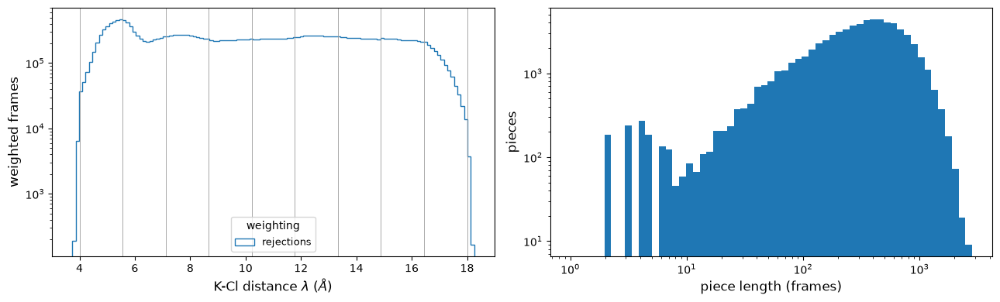

In [4]:
def prepare(weighting):
    parser = argparse.ArgumentParser()
    tis_data.add_data_arguments(parser)
    argv = [TIS_DIR, '--burn-in-fraction', str(BURN_IN_FRACTION), '--thin', str(THIN)]
    if weighting is not None:
        argv += ['--weights', weighting]
    if H5_FILE is not None:
        argv += ['--h5', H5_FILE]
    if LAMBDA_A is not None:
        argv += ['--lambda-a', str(LAMBDA_A)]
    if LAMBDA_B is not None:
        argv += ['--lambda-b', str(LAMBDA_B)]
    if PATHS_PER_ENSEMBLE is not None:
        argv += ['--paths-per-ensemble', str(PATHS_PER_ENSEMBLE)]
    if REVERSED:
        argv += ['--reversed']
    args = parser.parse_args(argv)
    data = tis_data.prepare_data(args)
    if CV_COLUMNS is not None:
        data.X = data.X_all[:, list(CV_COLUMNS)]     # the CVs of the fit (X_all keeps every column of order.txt)
    return args.weights, args.lambda_a, args.lambda_b, data     # the weighting actually used


# None = the run's default (section 3); the same weighting twice is fitted once
names = list(dict.fromkeys(w if w is not None else default_w for w in WEIGHTINGS))
datas = {}
for weighting in names:
    name, lambda_a, lambda_b, data = prepare(weighting)
    datas[name] = data
    print(f'--> {name}: {len(data.lam)} frames, {data.i_traj.max() + 1} pieces, '
          f'{len(np.unique(data.group_traj))} paths\n')
data = next(iter(datas.values()))  # the frames are the same for every weighting
print(f'fit CVs ({data.X.shape[1]}): ' + (', '.join(data.cv_names) if hasattr(data, 'cv_names') else f'{data.X.shape[1]} column(s) of order.txt'))
free = ~(data.boundary0 | data.boundary1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
e_lam = np.linspace(data.lam.min(), data.lam.max(), 121)
for name, d in datas.items():
    ax1.hist(d.lam, bins=e_lam, weights=d.path_weights, histtype='step', label=name)
for v in settings['interfaces']:
    ax1.axvline(v, color='0.6', lw=0.6)
ax1.set(xlabel=LABEL, ylabel='weighted frames', yscale='log')
ax1.legend(title='weighting')
lengths = np.bincount(data.i_traj)
ax2.hist(lengths, bins=np.logspace(0, np.log10(lengths.max() + 1), 60))
ax2.set(xscale='log', yscale='log', xlabel='piece length (frames)', ylabel='pieces')
fig.tight_layout()
plt.show()

## 5. Exact Committor

None: there is no reference for an explicit-solvent MD system (the exact committor of the toy systems comes from the engine's discrete chain, which is known there). `q_exact_of = None` makes the fit skip the RMS against the exact committor; the plots then show only the fit.


In [5]:
q_exact_of = None


## 6. Fit the Committor

One fit per weighting (and per seed in `SEEDS`), on the same frames. `CommittorNE` with `group_traj` (the pieces of one path count as one unit in the error estimates), the **A/B ends as traps** (`set_fixed_traj_length_trap`: longer than any piece plus the longest Z_q lag, so no window is dropped), and the **stopped ends** (`set_stopped_traj_end`, `STOPPED_ENDS`): a piece that ends outside A and B was stopped by the path's own end (a turn), so a window that passes it uses q at that end instead of being dropped, which would condition on the path not stopping earlier.

The first cell defines the plots, the progress line and the piece ends; the second builds the committor, runs `fit_transform` for the warm-up (wide envelope) and then in chunks of `CHUNK` iterations (it continues from the current q), and `seed_runs.save_and_show` shows and saves after the warm-up and every chunk as `<OUT>/<weighting>/seed<s>/it<N>_<plot>.png`:
- `metrics`: `dr2`, `zqs_z` and `|dx|` over the iterations. **Convergence: `zqs_z`** (the worst |stopped Z_q / standard error| over q and lags) about 2 or less, with `|dx|` small. For pieces cut at M the stopped Z_q of the committor is 0 at every q and lag (notes §5, §8.1);
- `tis`: the stopped Z_q per lag, the short-lag Z_q and the stopped observed-vs-predicted;
- `feps`, `obs_pred` (if listed in `PLOTS`): the library's original plots, biased for path pieces; with `STOPPED_ENDS` the Z_q of `feps` is the stopped one;
- `q_profile`: the path-weighted mean q per λ bin next to the exact committor, and fit − exact;

The progress line gives the path-weighted RMS(fit − exact) over the frames with 0.05 < q_exact < 0.95. Each weighting's final q per frame is kept in `fits` for section 7.

In [6]:
def edges_for(d):
    return (np.linspace(lambda_a, lambda_b, N_BINS + 1),)


def extras_for(d, qe):
    # q -> figure: the path-weighted mean q per lambda bin, against the exact committor
    edges = edges_for(d)
    fr = ~(d.boundary0 | d.boundary1)
    bm = seed_runs.BinnedMean((d.lam,), edges[:1], fr)
    w_mean = bm(d.path_weights)
    mid = (edges[0][1:] + edges[0][:-1]) / 2
    prof_ex = None if qe is None else bm(d.path_weights * qe) / w_mean

    def q_profile(q):
        P = bm(d.path_weights * cp.asnumpy(q.r_traj)) / w_mean
        fig, axes = plt.subplots(1, 1 if qe is None else 2, figsize=(6 if qe is None else 13, 4), squeeze=False)
        axes[0, 0].plot(mid, P, label='fit')
        if qe is not None:
            axes[0, 0].plot(mid, prof_ex, 'k--', label='exact')
            t = (prof_ex > 0.05) & (prof_ex < 0.95)
            axes[0, 1].plot(mid, P - prof_ex)
            axes[0, 1].axhline(0, color='k', lw=0.8)
            axes[0, 1].set(xlabel=XLABEL, ylabel='fit $-$ exact',
                           title=f'RMS per bin (0.05 < exact < 0.95) {np.sqrt(np.nanmean((P - prof_ex)[t] ** 2)):.4f}')
            axes[0, 1].grid(alpha=0.3)
        axes[0, 0].set(xlabel=XLABEL, ylabel='$q$ (mean per bin)')
        axes[0, 0].legend()
        axes[0, 0].grid(alpha=0.3)
        fig.tight_layout()
        return fig

    extras = {'q_profile': q_profile}
    return extras


def report_for(d, qe):
    # progress line: path-weighted RMS(fit - exact) over the frames with 0.05 < q_exact < 0.95
    if qe is None:
        return None
    trans = ~(d.boundary0 | d.boundary1) & (qe > 0.05) & (qe < 0.95)
    idx, qe_g, w_g = (cp.asarray(a) for a in (np.flatnonzero(trans), qe[trans], d.path_weights[trans]))

    def report(q):
        diff = q.r_traj[idx] - qe_g
        return f'| RMS(fit - exact) {float(cp.sqrt(cp.sum(w_g * diff * diff) / cp.sum(w_g))):.4f}'
    return report


XLABEL = LABEL

# ---- piece ends: in A or B (trap), or stopped by the path's own end, a turn (stopped end)
# (the frames are the same for every weighting, so this is done once)
b_all = data.boundary0 | data.boundary1
piece_end = np.r_[np.flatnonzero(np.diff(data.i_traj)), len(data.i_traj) - 1]      # last frame of every piece
stop_end = np.zeros(len(b_all), bool)
stop_end[piece_end] = ~b_all[piece_end]
longest = int(np.bincount(data.i_traj - data.i_traj.min()).max())
TRAP_LEN = max(2 ** 16, longest + 2 ** 15 + 1)         # A/B trap: longer than any piece plus the longest Z_q lag (2^15)
print(f'{len(piece_end)} pieces: {stop_end.sum()} end at a turn (stopped), {len(piece_end) - stop_end.sum()} in A or B; '
      f'longest piece {longest} frames, A/B trap {TRAP_LEN}')

PRINT_STEP = min(500, CHUNK, WARMUP_ITER or CHUNK)    # the metrics are recorded every PRINT_STEP iterations (a plot needs a record)
METRICS = ['delta_r2', 'max_z_zq_stopped', 'delta_x']


def show_stage(q, folder, n_done, stage, extras, report):
    """Save and show the plots after a stage (<folder>/it<N>_<plot>.png), and print the progress."""
    seed_runs.save_and_show(q, folder, f'it{n_done}', PLOTS, dict(metrics=METRICS), extras)
    print(f'{n_done} iterations ({stage}) {"" if report is None else report(q)}', flush=True)


69258 pieces: 57593 end at a turn (stopped), 11665 in A or B; longest piece 2828 frames, A/B trap 65536


===== fit, weighting rejections, seed 0 =====
#=500, dr2=969.139, zqs_z=19.4479, sdzqs=645.622, |dx|=0.117858, time=45.7667
#=1000, dr2=984.169, zqs_z=19.3997, sdzqs=612.642, |dx|=0.0436613, time=91.1552
#=1500, dr2=1019.37, zqs_z=19.4334, sdzqs=633.789, |dx|=0.0392052, time=136.502
#=2000, dr2=1063.56, zqs_z=19.4223, sdzqs=680.669, |dx|=0.0346013, time=182.603


/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seed0/it2000 ---


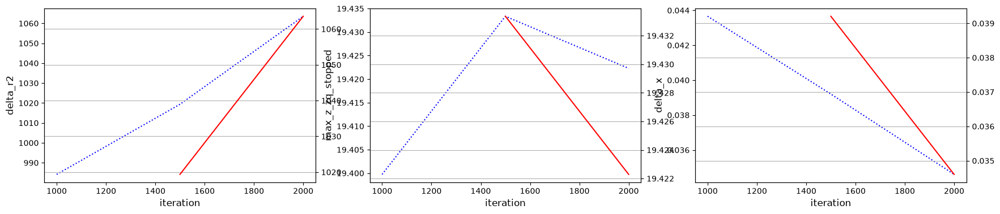

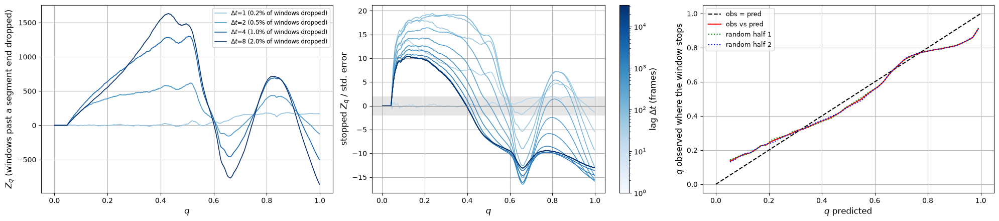

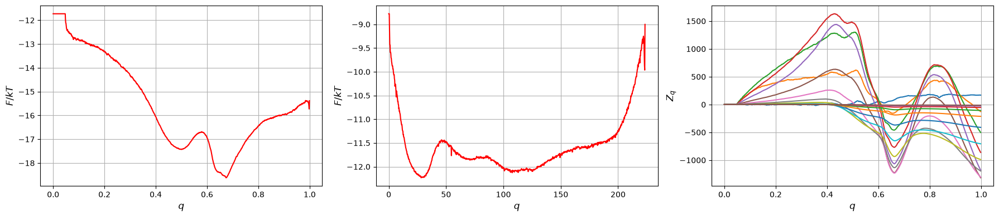

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


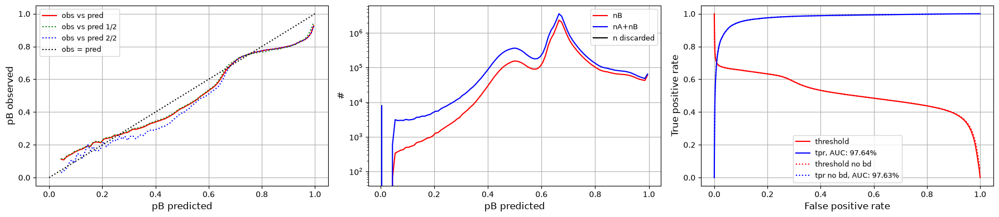

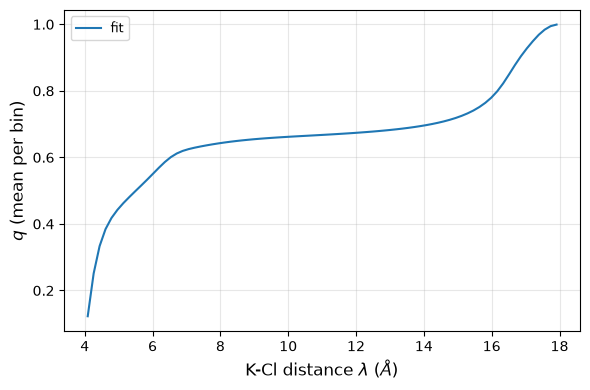

2000 iterations (warm-up, envelope 1) 
#=2500, dr2=1105.19, zqs_z=19.4186, sdzqs=722.22, |dx|=0.0260505, time=45.9138
#=3000, dr2=1148.11, zqs_z=19.4242, sdzqs=763.986, |dx|=0.0239527, time=91.7939
#=3500, dr2=1192.68, zqs_z=19.3967, sdzqs=807.425, |dx|=0.0208149, time=137.209
#=4000, dr2=1234.3, zqs_z=19.3673, sdzqs=842.948, |dx|=0.019007, time=182.625
#=4500, dr2=1278.33, zqs_z=19.4047, sdzqs=877.726, |dx|=0.0177141, time=228.02


/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seed0/it4500 ---


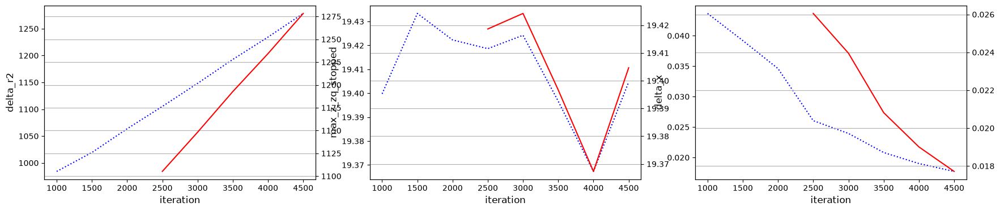

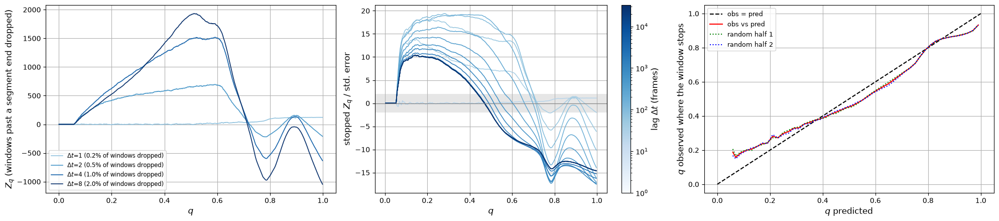

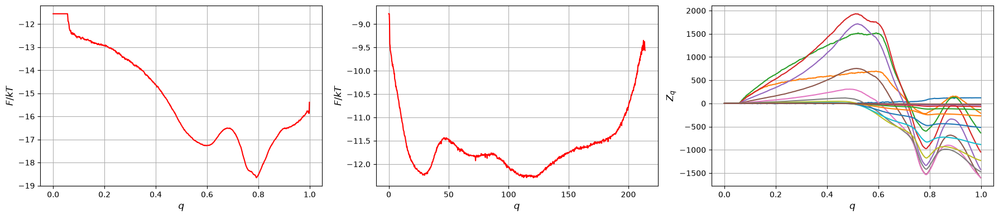

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


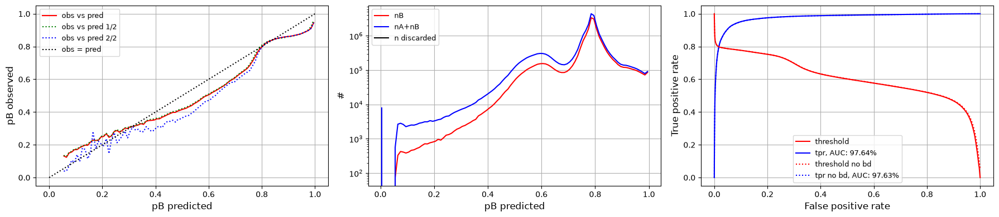

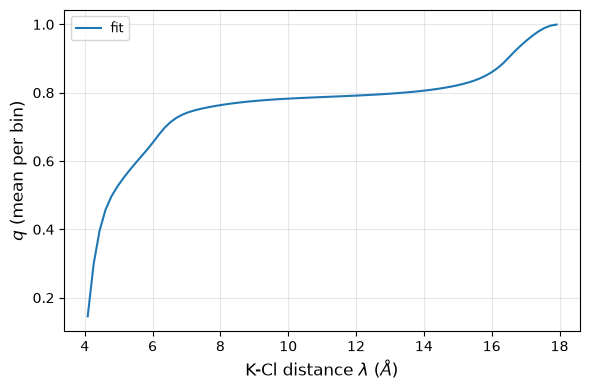

4500 iterations (main, envelope 0.01) 
#=5000, dr2=1320.39, zqs_z=19.3867, sdzqs=908.067, |dx|=0.0159331, time=45.2507
#=5500, dr2=1363.38, zqs_z=19.448, sdzqs=934.086, |dx|=0.0152339, time=90.6906
#=6000, dr2=1404.82, zqs_z=19.4366, sdzqs=956.743, |dx|=0.0139406, time=136.845
#=6500, dr2=1441.24, zqs_z=19.4136, sdzqs=972.651, |dx|=0.0119154, time=182.349
#=7000, dr2=1474.68, zqs_z=19.4309, sdzqs=986.291, |dx|=0.0105195, time=227.853


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seed0/it7000 ---


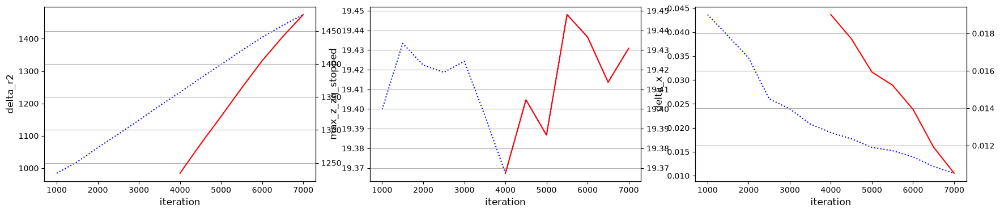

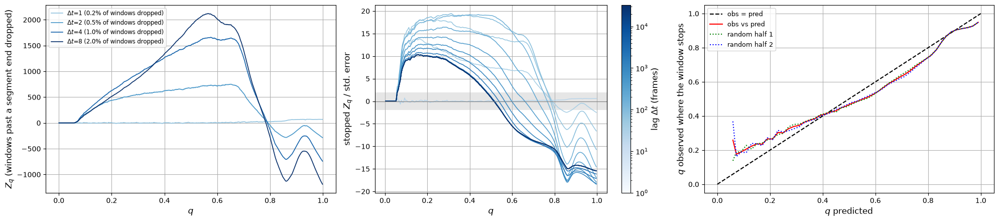

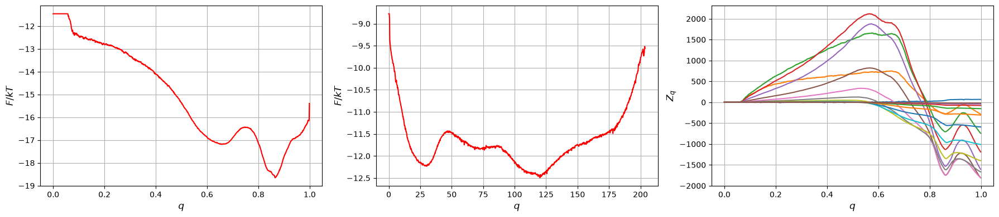

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


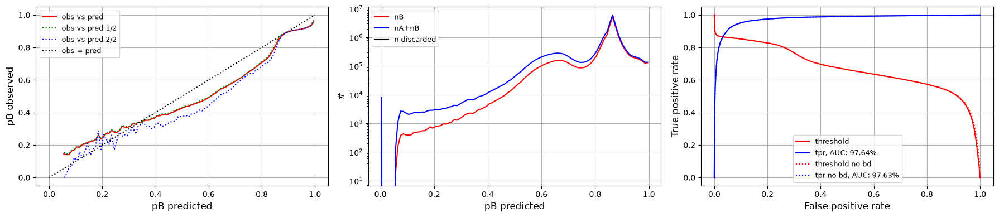

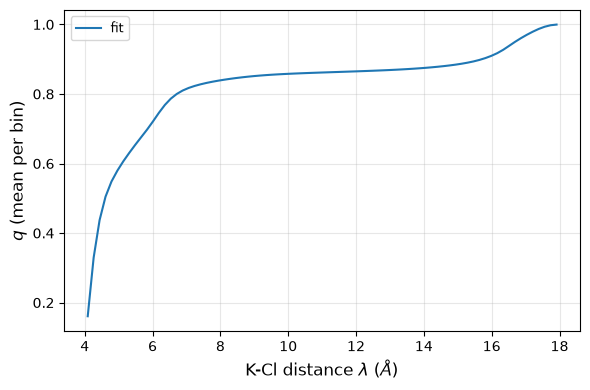

7000 iterations (main, envelope 0.01) 
#=7500, dr2=1505.9, zqs_z=19.3794, sdzqs=998.874, |dx|=0.00927749, time=45.3397
#=8000, dr2=1532.9, zqs_z=19.3909, sdzqs=1007.51, |dx|=0.00795529, time=90.8654
#=8500, dr2=1557.37, zqs_z=19.3852, sdzqs=1013.37, |dx|=0.00712661, time=136.435
#=9000, dr2=1581.9, zqs_z=19.3989, sdzqs=1020.29, |dx|=0.0067028, time=181.962
#=9500, dr2=1601.48, zqs_z=19.3752, sdzqs=1025.14, |dx|=0.00537836, time=227.556


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seed0/it9500 ---


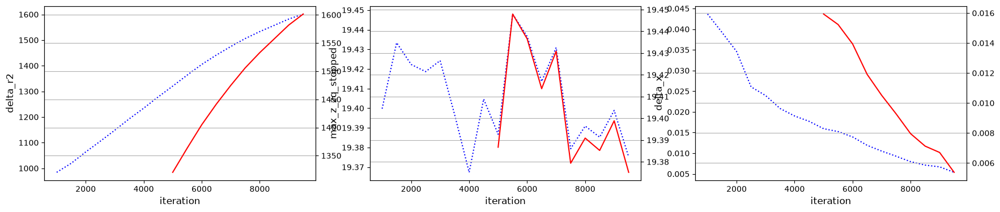

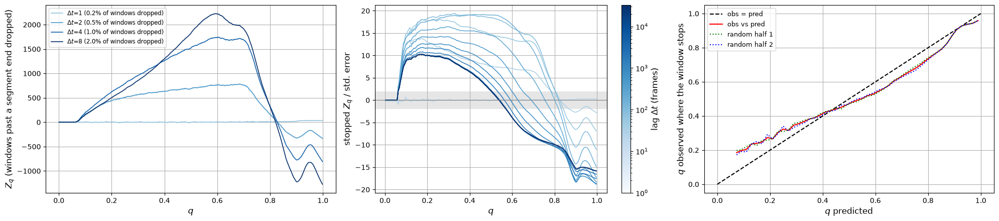

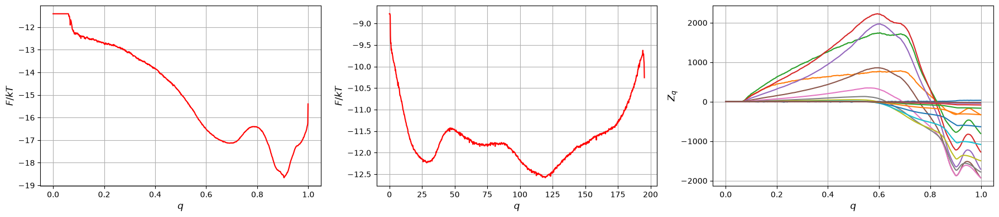

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


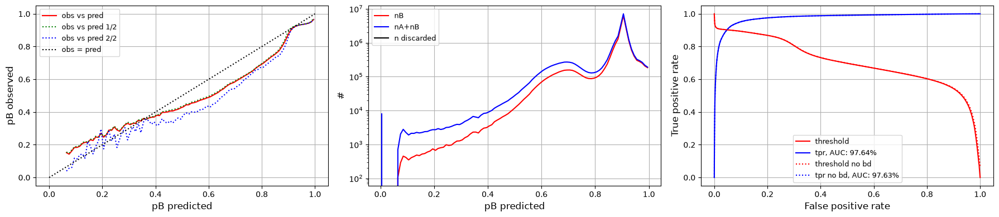

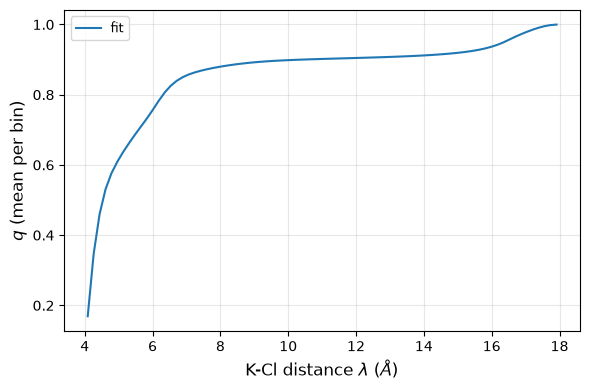

9500 iterations (main, envelope 0.01) 
#=10000, dr2=1620.02, zqs_z=19.4079, sdzqs=1026.79, |dx|=0.00508489, time=45.3637
#=10500, dr2=1636.72, zqs_z=19.4033, sdzqs=1028.92, |dx|=0.00454369, time=90.7812
#=11000, dr2=1650.55, zqs_z=19.3876, sdzqs=1031.53, |dx|=0.00359159, time=136.149
#=11500, dr2=1663.95, zqs_z=19.4022, sdzqs=1032.87, |dx|=0.00345135, time=181.544
#=12000, dr2=1675.77, zqs_z=19.4396, sdzqs=1032.89, |dx|=0.00320575, time=227


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seed0/it12000 ---


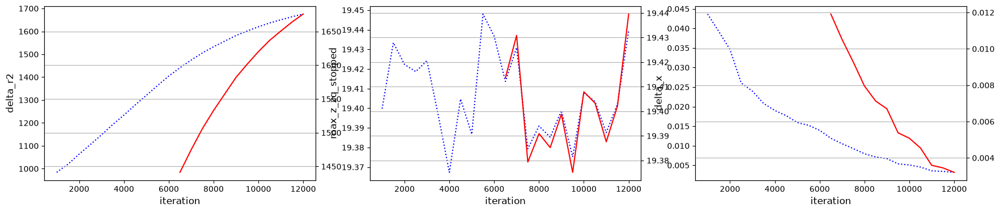

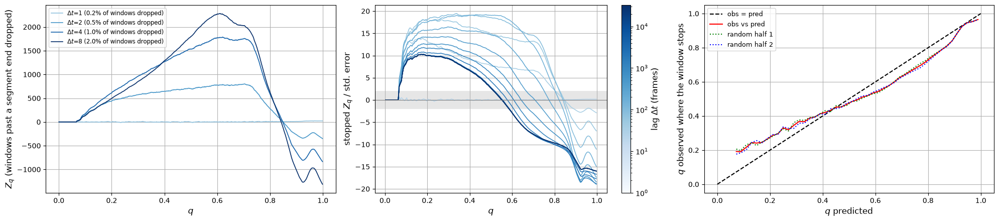

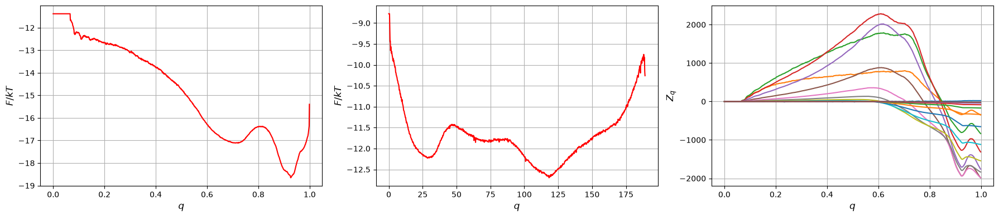

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


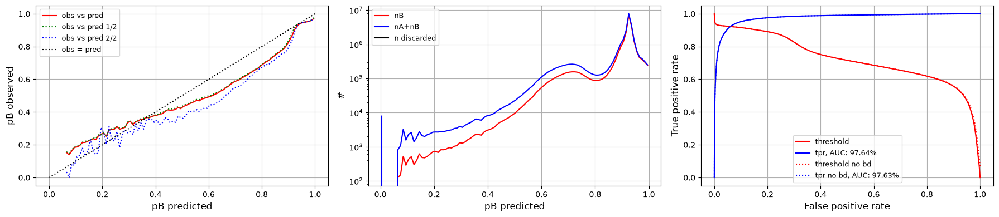

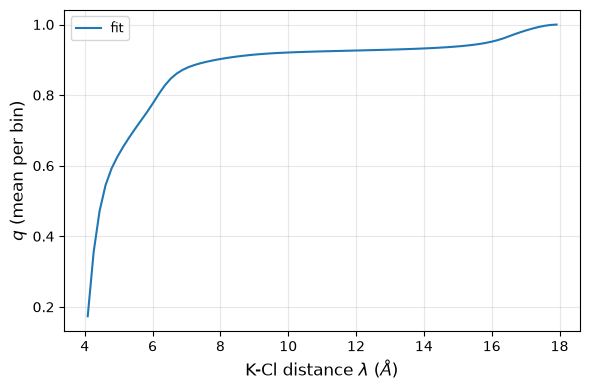

12000 iterations (main, envelope 0.01) 
#=12500, dr2=1687.46, zqs_z=19.3805, sdzqs=1034.28, |dx|=0.00292616, time=45.3804
#=13000, dr2=1698.16, zqs_z=19.3831, sdzqs=1034.86, |dx|=0.0027119, time=91.7311
#=13500, dr2=1707.45, zqs_z=19.4061, sdzqs=1034.81, |dx|=0.00240435, time=137.451
#=14000, dr2=1715.64, zqs_z=19.3991, sdzqs=1035.18, |dx|=0.00207577, time=183.045
#=14500, dr2=1722.5, zqs_z=19.4129, sdzqs=1034.85, |dx|=0.00173218, time=228.631


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seed0/it14500 ---


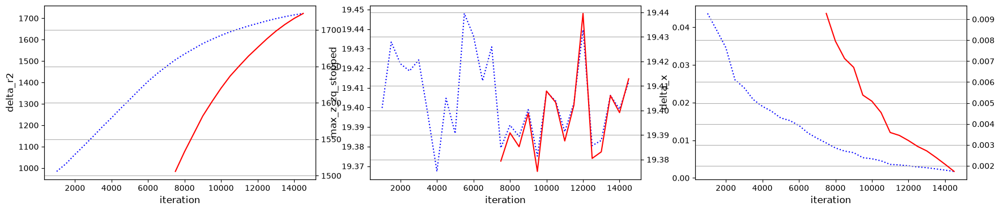

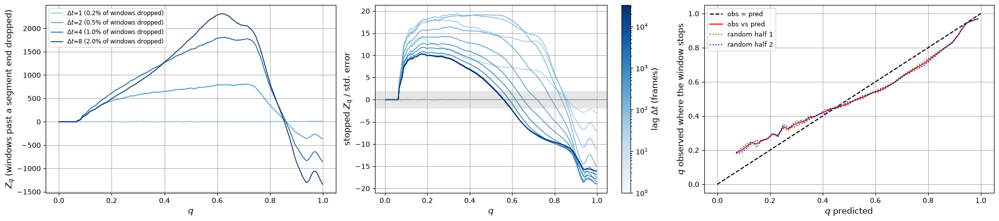

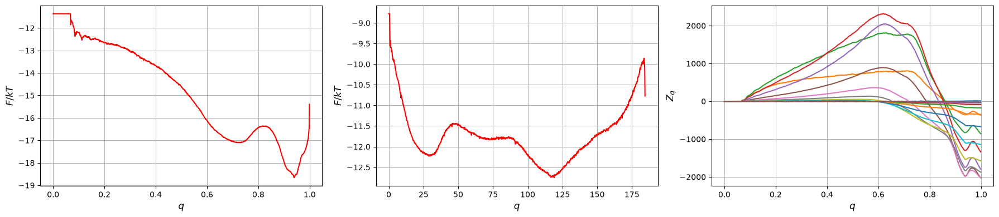

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


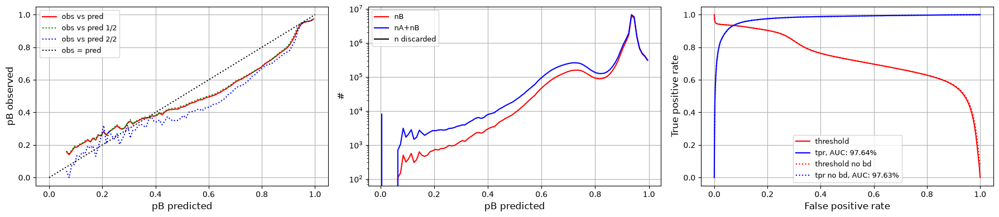

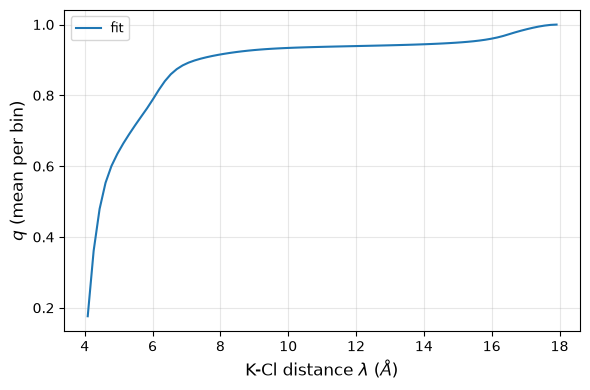

14500 iterations (main, envelope 0.01) 
#=15000, dr2=1728.91, zqs_z=19.4032, sdzqs=1034.93, |dx|=0.00160524, time=45.1984
#=15500, dr2=1734.99, zqs_z=19.3831, sdzqs=1034.44, |dx|=0.00155645, time=90.828
#=16000, dr2=1740.65, zqs_z=19.383, sdzqs=1034.39, |dx|=0.00139888, time=136.473
#=16500, dr2=1745.4, zqs_z=19.3928, sdzqs=1034.22, |dx|=0.00117211, time=182.144
#=17000, dr2=1749.58, zqs_z=19.4238, sdzqs=1033.99, |dx|=0.00105545, time=227.831


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seed0/it17000 ---


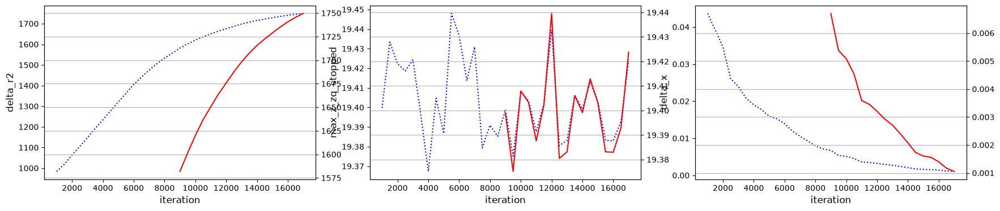

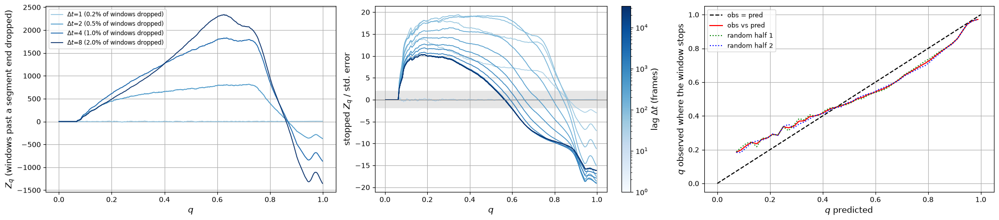

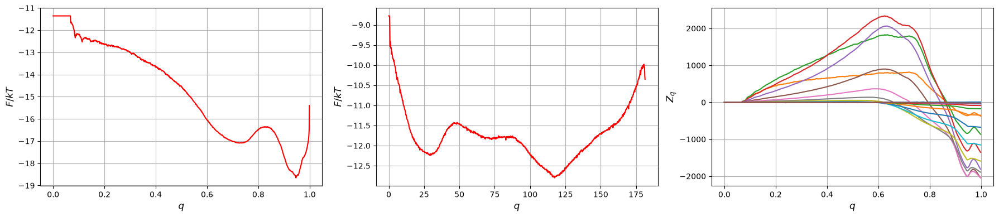

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


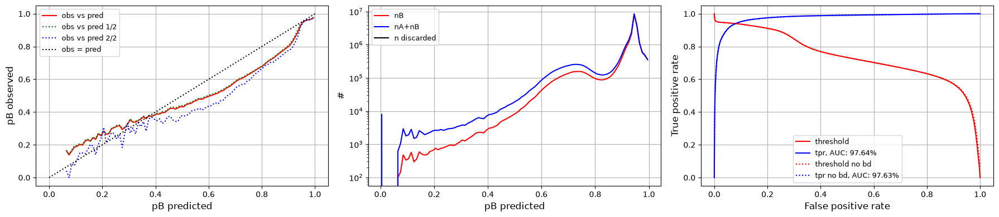

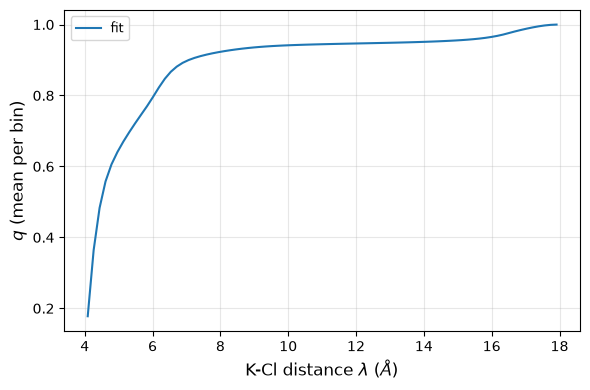

17000 iterations (main, envelope 0.01) 


In [8]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
fits = {}                                      # weighting -> final q per seed, exact committor, fit time, zqs_z history
for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    #qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    qe = None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seed{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=WARMUP_ITER, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=n_iter, **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        #del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

In [13]:
del q

===== fit, weighting rejections, seed 0 =====
#=500, dr2=2486.26, zqs_z=28.1548, sdzqs=566.424, |dx|=0.115282, time=45.8213
#=1000, dr2=2489.77, zqs_z=27.4895, sdzqs=540.705, |dx|=0.00814117, time=91.3037
#=1500, dr2=2480.45, zqs_z=27.2343, sdzqs=525.788, |dx|=0.00297536, time=137.549
#=2000, dr2=2479.84, zqs_z=27.0643, sdzqs=519.22, |dx|=0.00148051, time=183.769
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it2000 ---


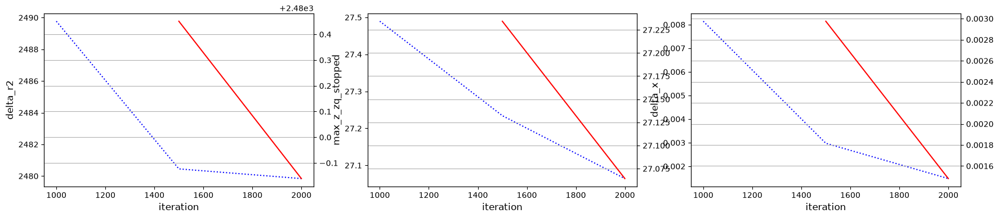

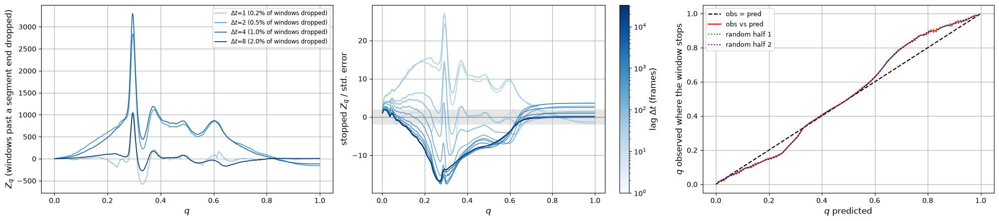

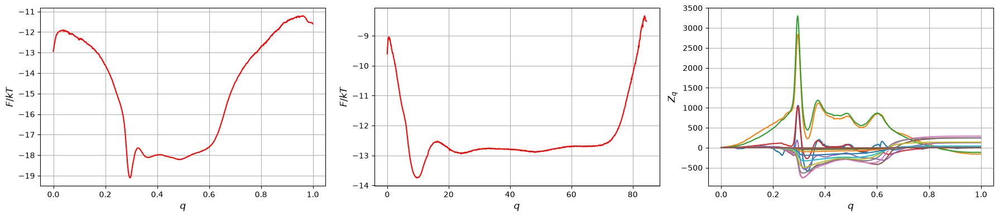

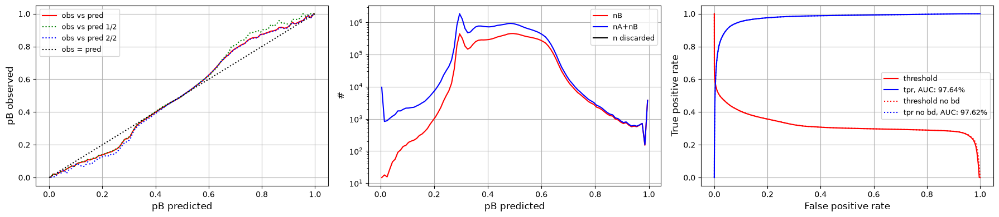

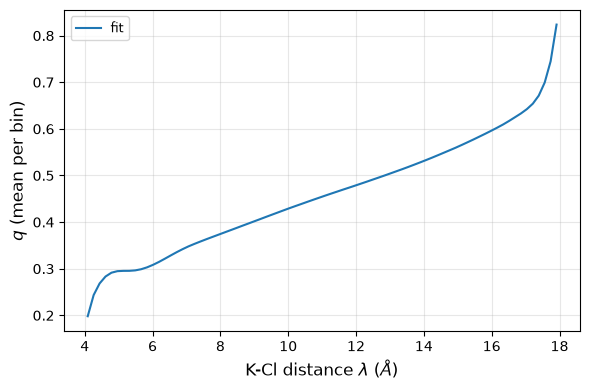

2000 iterations (warm-up, envelope 1) 
#=2500, dr2=2471.68, zqs_z=21.8175, sdzqs=437.827, |dx|=0.0018846, time=45.6208
#=3000, dr2=2471.34, zqs_z=21.923, sdzqs=437.511, |dx|=0.00041596, time=91.636
#=3500, dr2=2473.85, zqs_z=22.4273, sdzqs=440.521, |dx|=0.000607943, time=137.18
#=4000, dr2=2474.16, zqs_z=22.4065, sdzqs=441.133, |dx|=0.000209338, time=182.718
#=4500, dr2=2475.23, zqs_z=22.4332, sdzqs=441.632, |dx|=0.000606572, time=228.262
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it4500 ---


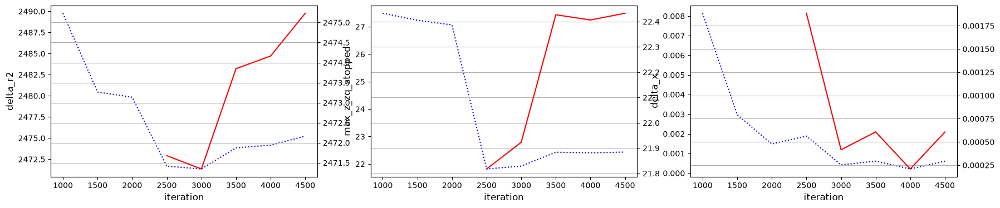

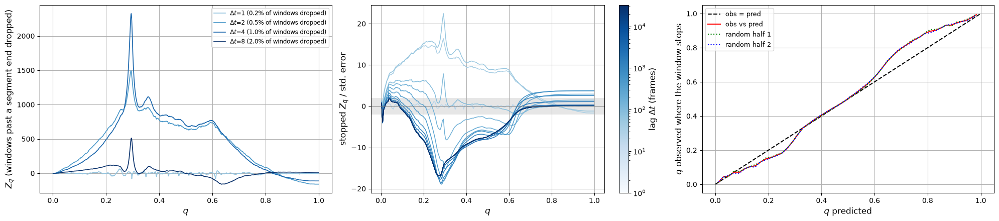

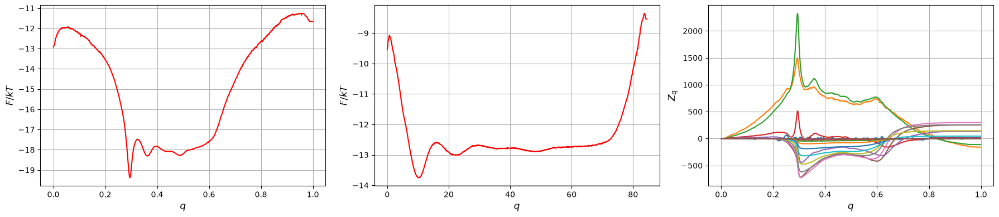

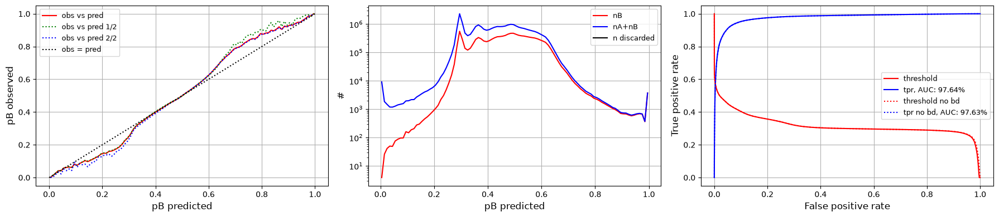

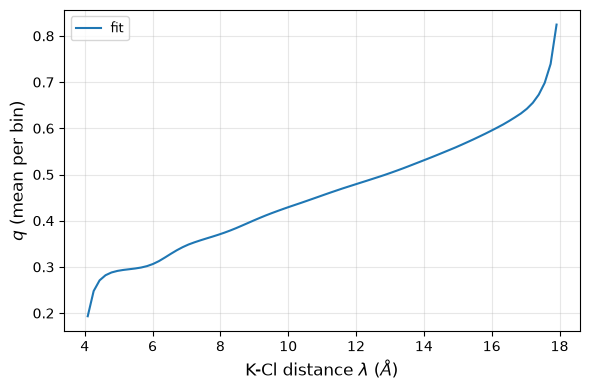

4500 iterations (main, envelope 0.01) 
#=5000, dr2=2474.19, zqs_z=22.4689, sdzqs=440.568, |dx|=0.000288557, time=45.5991
#=5500, dr2=2474.05, zqs_z=22.3638, sdzqs=440.055, |dx|=0.000137138, time=90.9463
#=6000, dr2=2474.6, zqs_z=22.407, sdzqs=440.868, |dx|=0.000107665, time=136.566
#=6500, dr2=2474.46, zqs_z=22.5032, sdzqs=441.114, |dx|=6.06358e-05, time=182.641
#=7000, dr2=2475.47, zqs_z=22.5477, sdzqs=442.173, |dx|=0.000226055, time=227.994
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it7000 ---


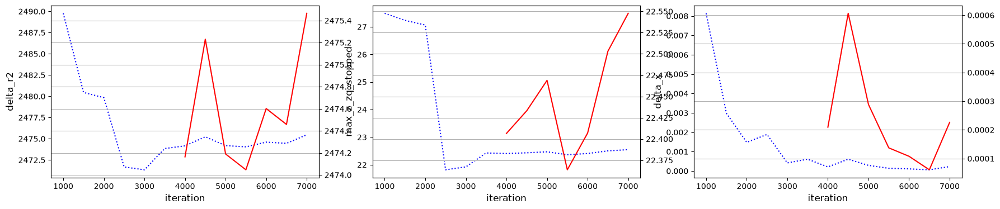

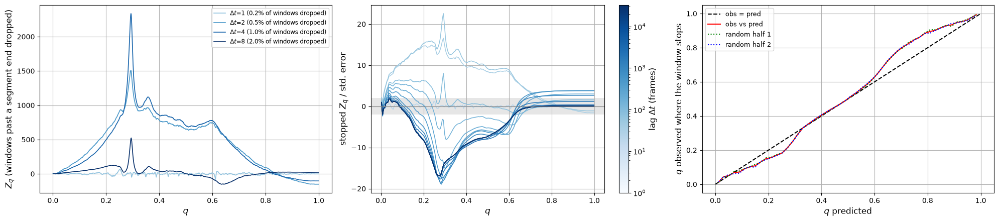

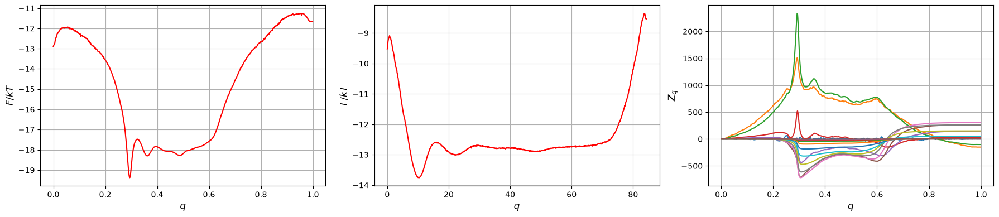

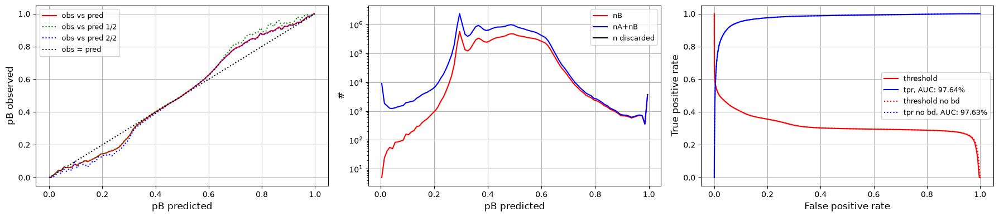

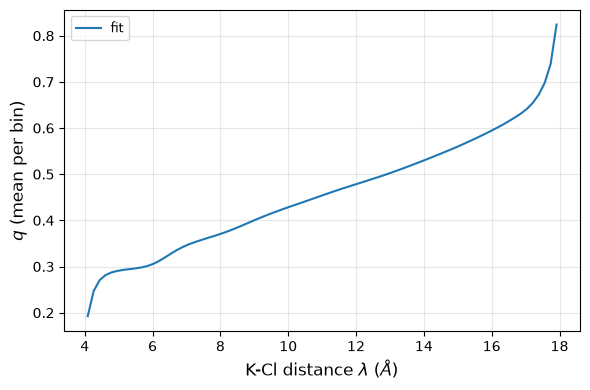

7000 iterations (main, envelope 0.01) 
#=7500, dr2=2476.51, zqs_z=22.5114, sdzqs=442.846, |dx|=0.000324861, time=45.3559
#=8000, dr2=2476.4, zqs_z=22.4019, sdzqs=442.948, |dx|=0.000195462, time=91.5509
#=8500, dr2=2476.39, zqs_z=22.325, sdzqs=442.723, |dx|=0.00031053, time=137.366
#=9000, dr2=2476.39, zqs_z=22.2743, sdzqs=443.164, |dx|=0.000186557, time=182.946
#=9500, dr2=2476.59, zqs_z=22.2555, sdzqs=442.942, |dx|=8.97952e-05, time=228.507
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it9500 ---


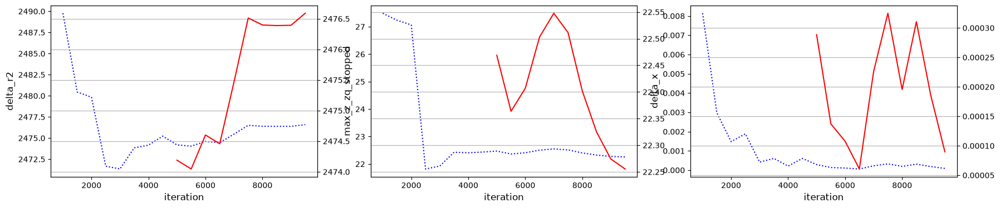

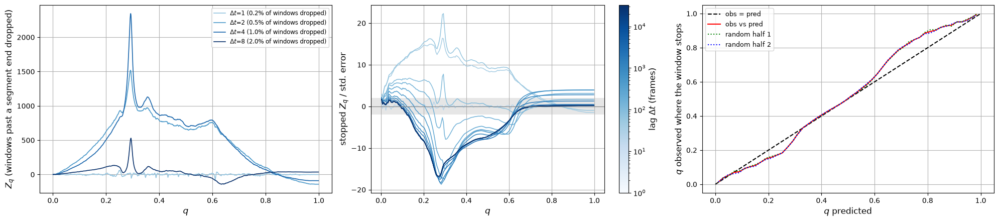

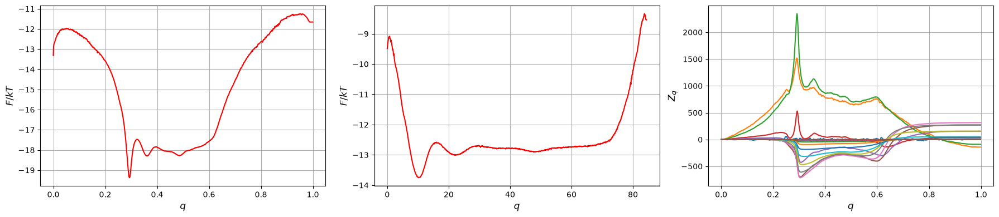

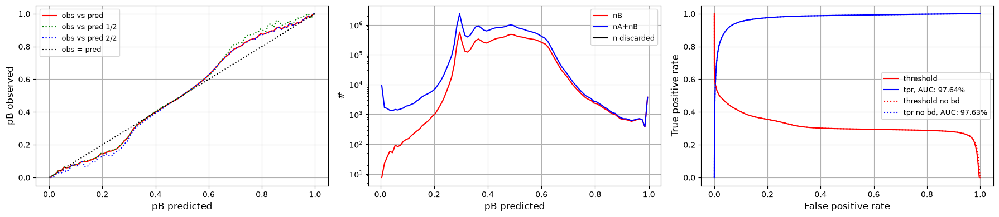

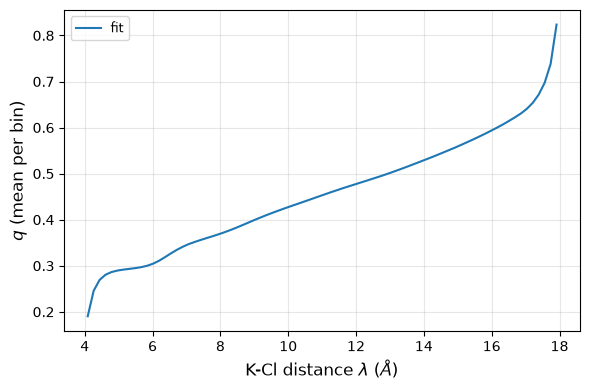

9500 iterations (main, envelope 0.01) 

Training interrupted at iteration 9856; keeping the RC of the last completed update.
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it12000 ---


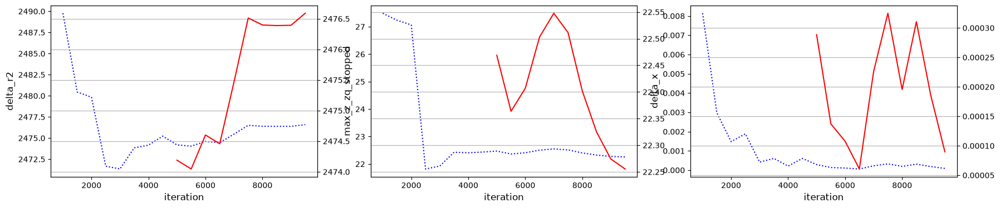

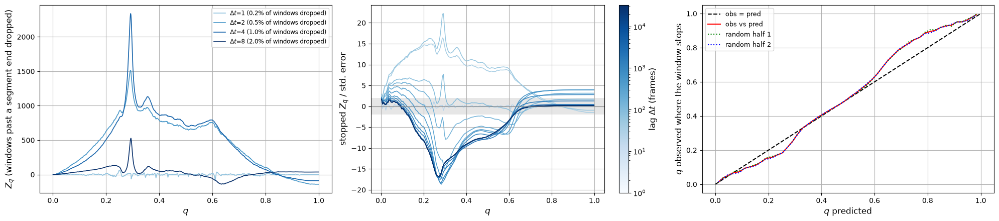

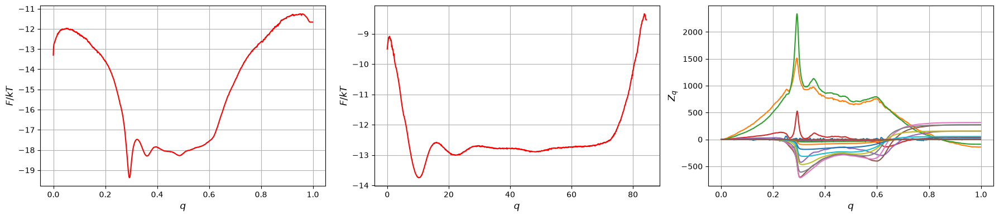

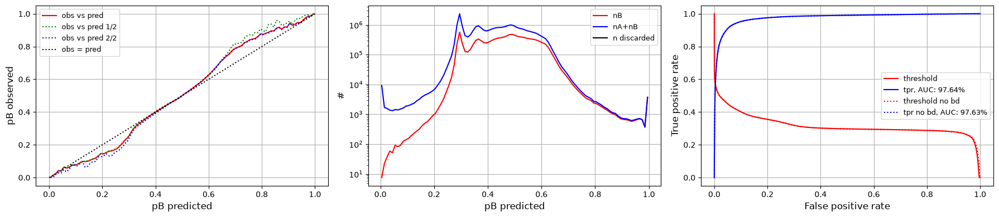

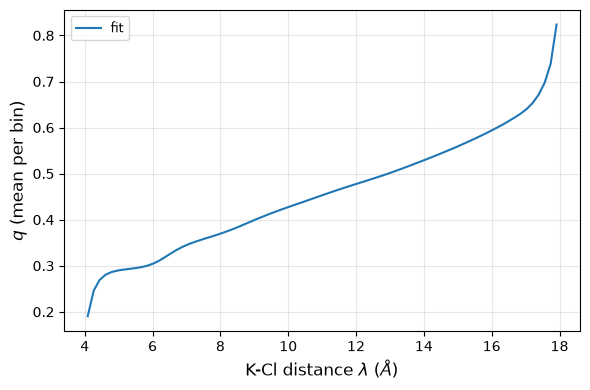

12000 iterations (main, envelope 0.01) 

Training interrupted at iteration 10000; keeping the RC of the last completed update.


KeyboardInterrupt: 

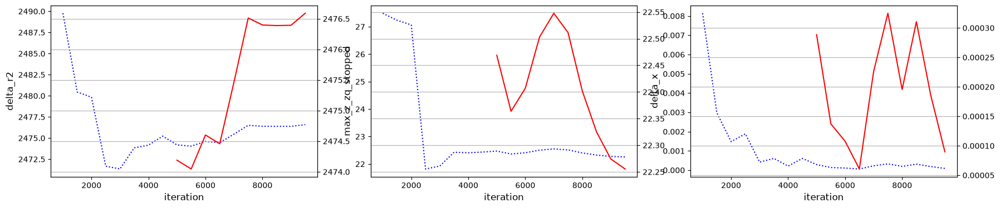

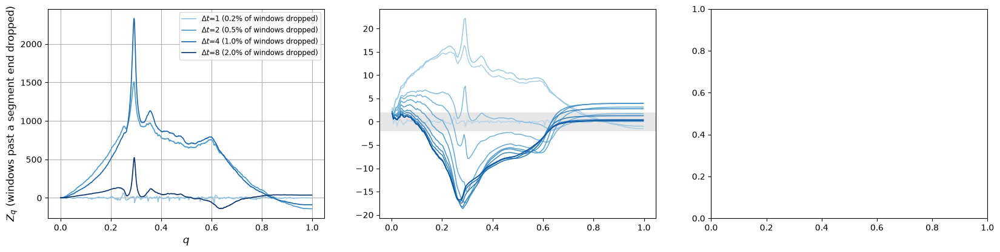

In [10]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
history=[0,1]
yr_type=['y(t-d),y(t)']
fits = {}                                      # weighting -> final q per seed, exact committor, fit time, zqs_z history
for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    #qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    qe = None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seedhist{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=WARMUP_ITER, 
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            delta_r2_max_change_allowed=10000, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=n_iter, 
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

===== fit, weighting rejections, seed 0 =====
#=500, dr2=1945.73, zqs_z=9.52087, sdzqs=171.473, |dx|=0.136734, time=45.8759
#=1000, dr2=1960.03, zqs_z=8.89178, sdzqs=147.651, |dx|=0.00710617, time=91.5474
#=1500, dr2=1963.28, zqs_z=8.95829, sdzqs=148.182, |dx|=0.00286168, time=137.925
#=2000, dr2=1937.79, zqs_z=9.06162, sdzqs=160.889, |dx|=0.00152987, time=184.302
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it2000 ---


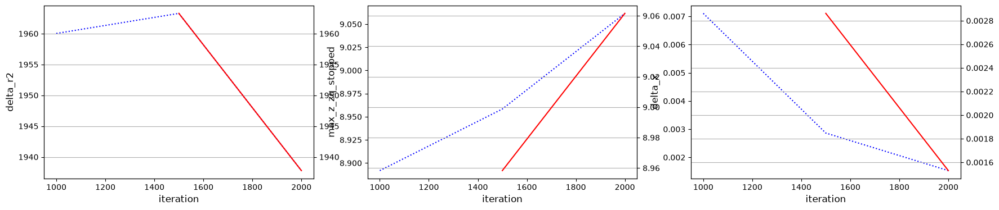

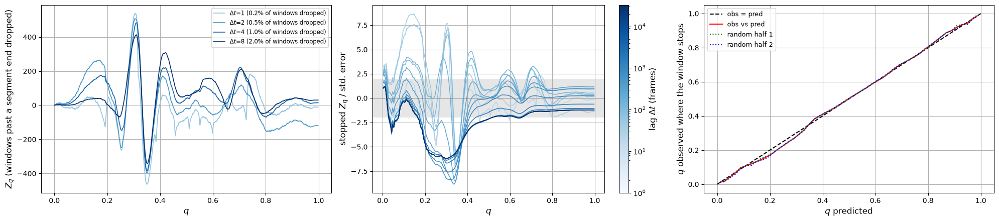

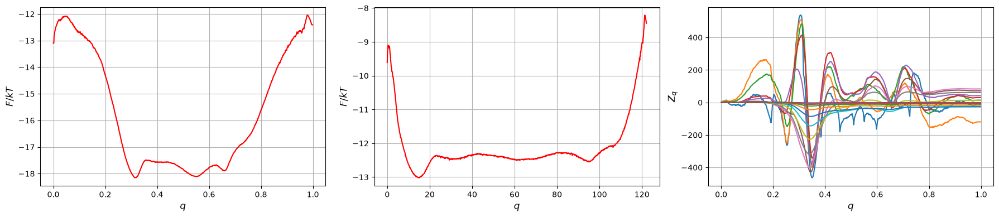

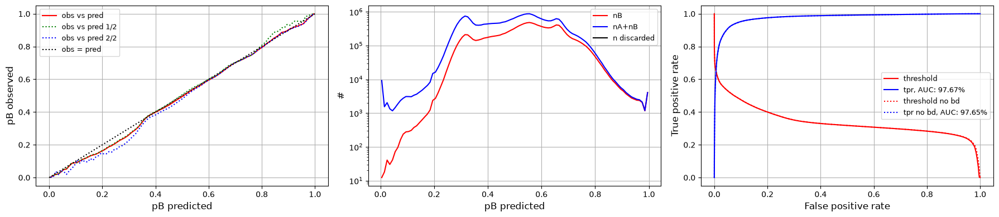

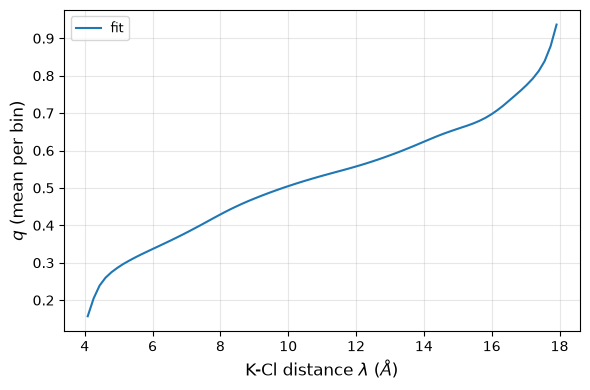

2000 iterations (warm-up, envelope 1) 
#=2500, dr2=1988.4, zqs_z=12.3426, sdzqs=108.94, |dx|=0.00772076, time=46.3398
#=3000, dr2=2006.69, zqs_z=12.1149, sdzqs=104.252, |dx|=0.00211121, time=92.0253
#=3500, dr2=2002.17, zqs_z=12.1658, sdzqs=105.247, |dx|=0.00170096, time=137.708
#=4000, dr2=1998.16, zqs_z=12.4525, sdzqs=104.182, |dx|=0.00118315, time=183.396
#=4500, dr2=2003.12, zqs_z=12.3819, sdzqs=104.919, |dx|=0.000431694, time=229.201
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it4500 ---


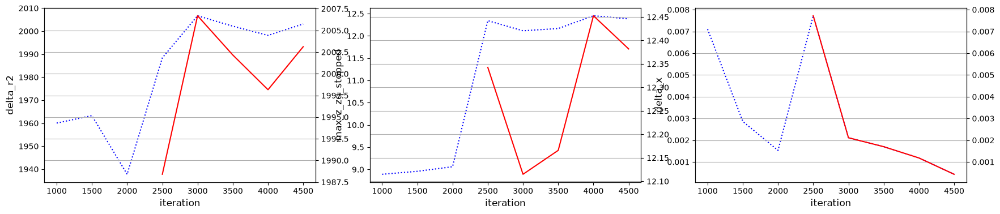

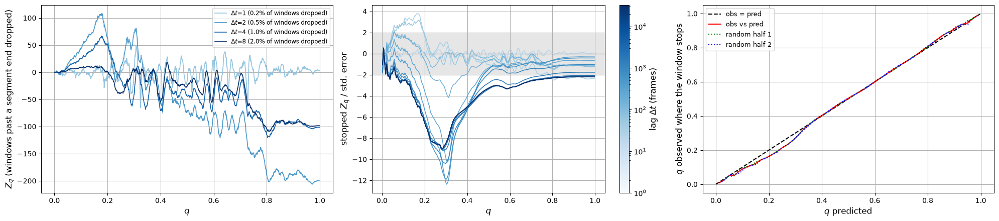

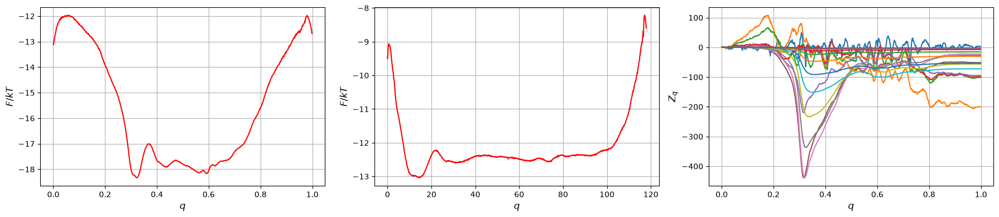

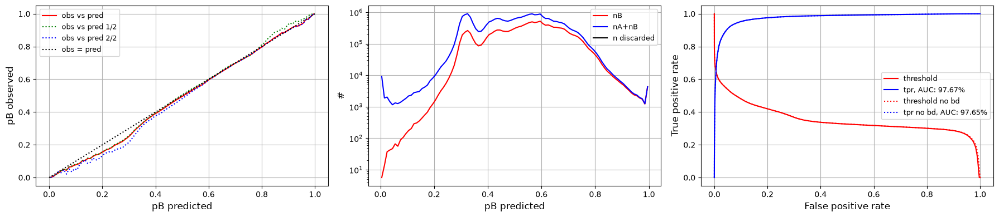

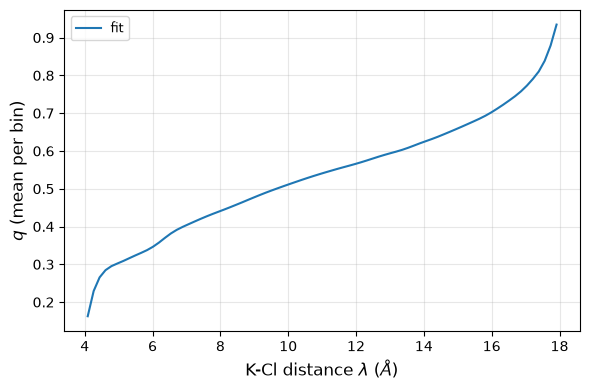

4500 iterations (main, envelope 0.01) 
#=5000, dr2=2005.05, zqs_z=12.4421, sdzqs=105.606, |dx|=0.000451561, time=45.684
#=5500, dr2=2001.25, zqs_z=12.3651, sdzqs=105.95, |dx|=0.000709754, time=91.4043
#=6000, dr2=2008.48, zqs_z=12.4594, sdzqs=106.054, |dx|=0.000346769, time=137.619
#=6500, dr2=2008.91, zqs_z=12.4006, sdzqs=105.769, |dx|=0.000379377, time=184.012
#=7000, dr2=2007.28, zqs_z=12.2897, sdzqs=106.292, |dx|=0.000371649, time=229.671
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it7000 ---


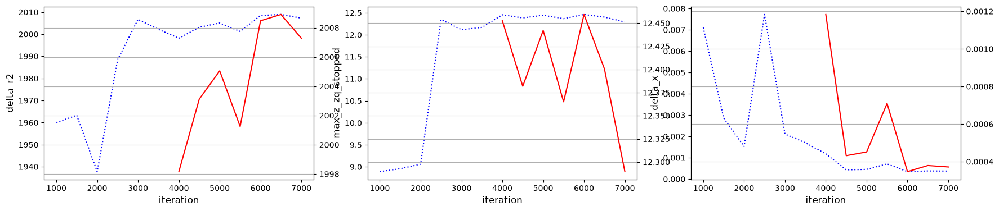

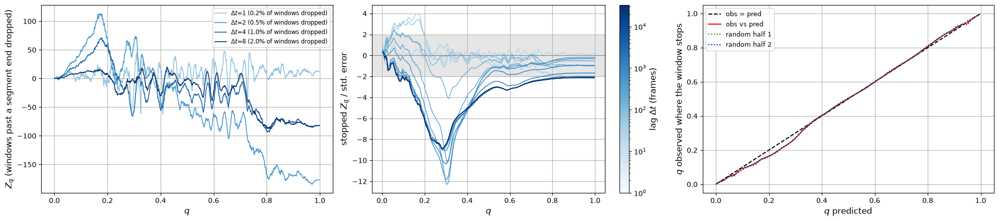

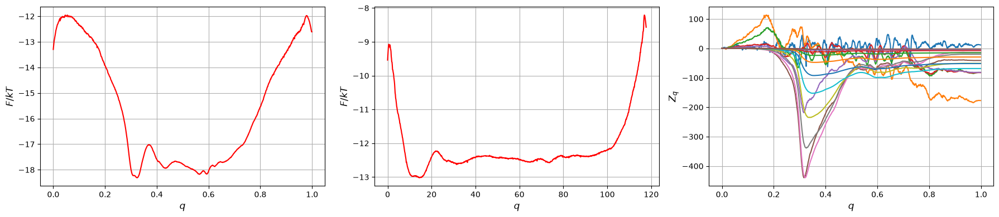

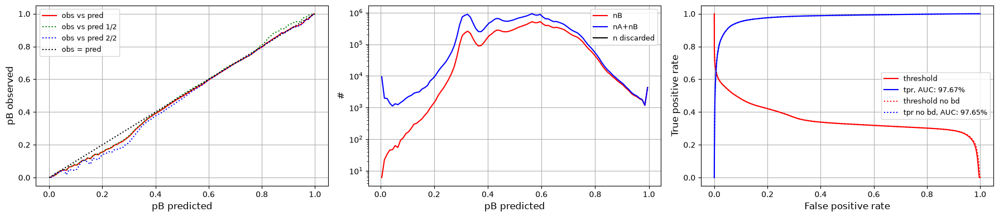

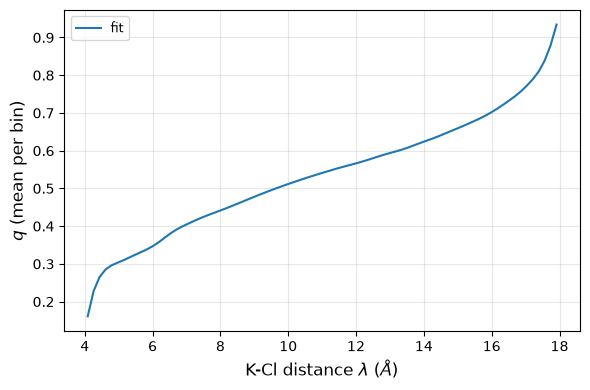

7000 iterations (main, envelope 0.01) 
#=7500, dr2=2006.25, zqs_z=12.4569, sdzqs=107.772, |dx|=0.000604778, time=45.4807
#=8000, dr2=2004.47, zqs_z=12.471, sdzqs=106.733, |dx|=0.00040471, time=91.1685
#=8500, dr2=2006.42, zqs_z=12.4695, sdzqs=106.749, |dx|=0.000316502, time=136.886
#=9000, dr2=2006.31, zqs_z=12.5313, sdzqs=107.45, |dx|=0.000288637, time=182.561
#=9500, dr2=2007.86, zqs_z=12.582, sdzqs=107.661, |dx|=0.000211524, time=228.239
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it9500 ---


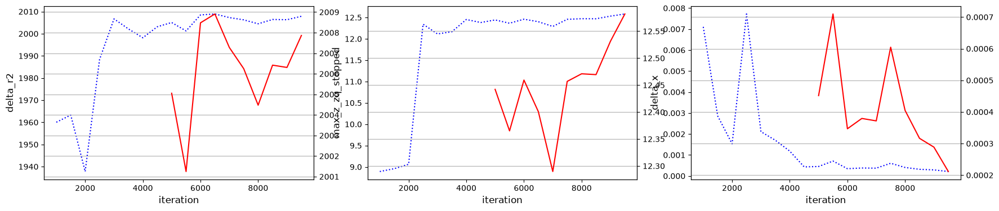

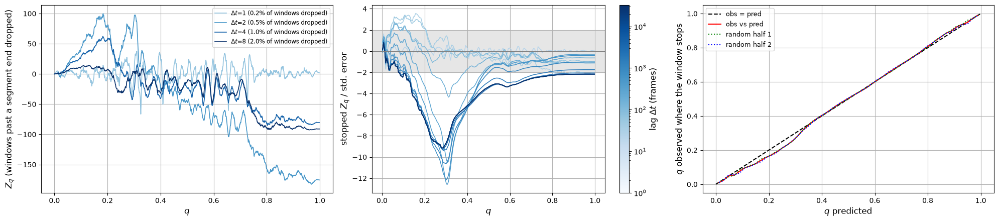

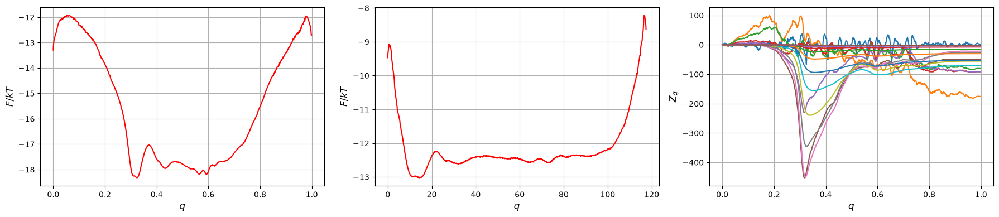

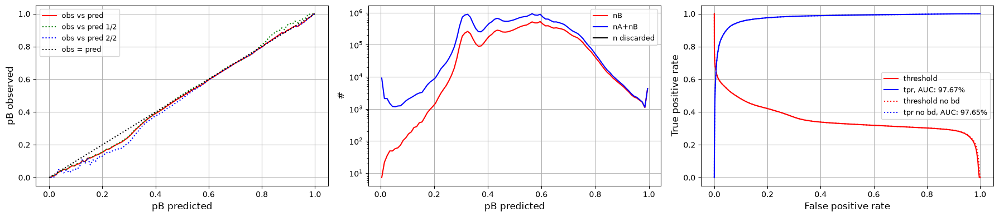

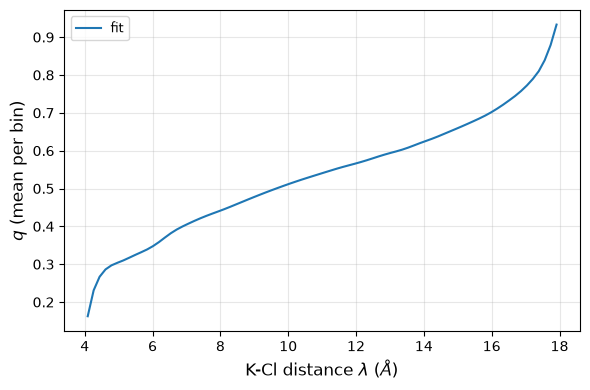

9500 iterations (main, envelope 0.01) 
#=10000, dr2=2008.1, zqs_z=12.5572, sdzqs=107.455, |dx|=0.000229869, time=45.5
#=10500, dr2=2008.79, zqs_z=12.5524, sdzqs=107.8, |dx|=0.000163206, time=91.1849
#=11000, dr2=2007.06, zqs_z=12.597, sdzqs=107.529, |dx|=0.000185421, time=137.603

Training interrupted at iteration 11500; keeping the RC of the last completed update.
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it12000 ---


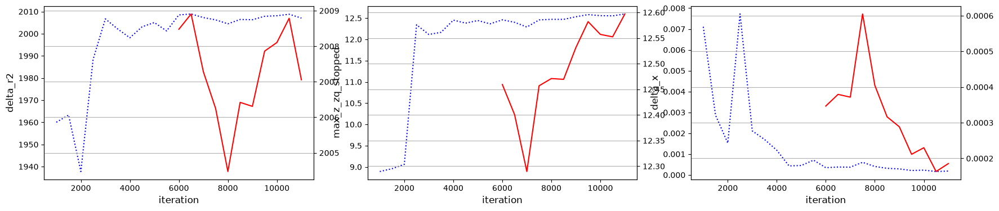

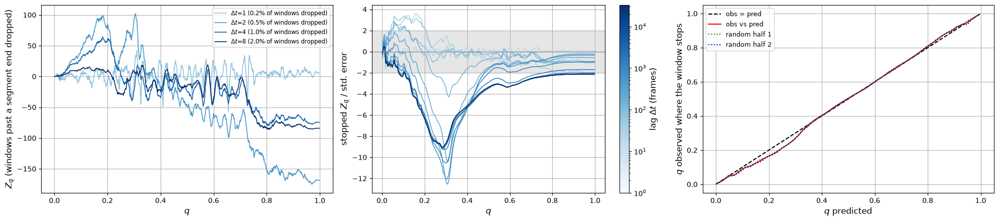

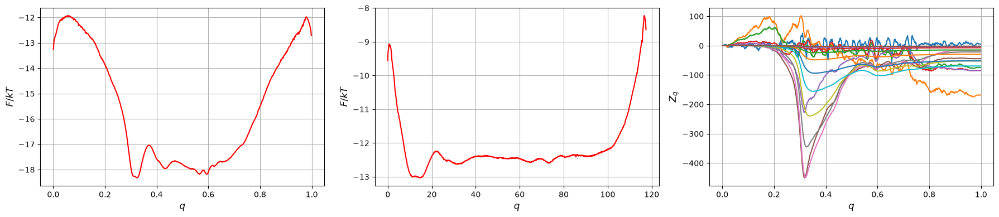

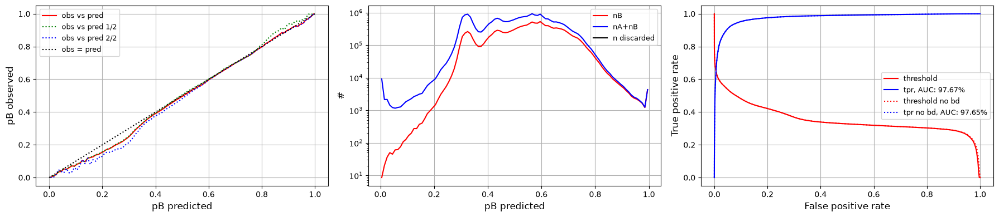

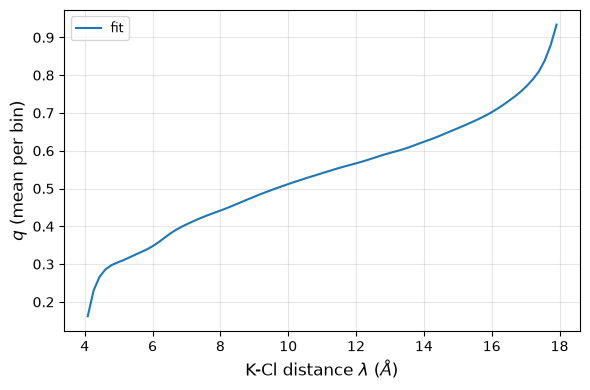

12000 iterations (main, envelope 0.01) 

Training interrupted at iteration 11972; keeping the RC of the last completed update.
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it14500 ---


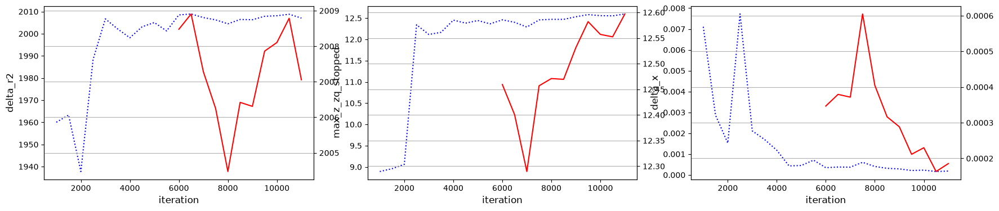

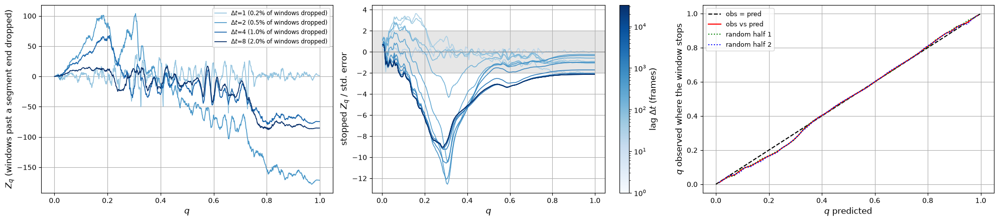

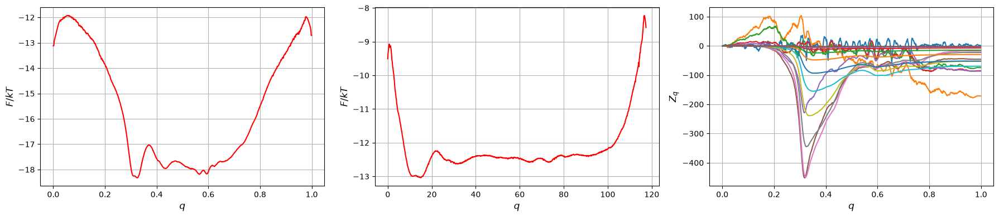

KeyboardInterrupt: 

In [11]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
history=[0,1,2,4]
yr_type=['y(t-d),y(t)']
fits = {}                                      # weighting -> final q per seed, exact committor, fit time, zqs_z history
for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    #qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    qe = None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seedhist{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=WARMUP_ITER, 
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            delta_r2_max_change_allowed=10000, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=n_iter, 
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

===== fit, weighting rejections, seed 0 =====
#=500, dr2=1593.11, zqs_z=15.614, sdzqs=222.203, |dx|=0.142486, time=46.502
#=1000, dr2=1633.13, zqs_z=16.1582, sdzqs=315.238, |dx|=0.0119978, time=92.4743
#=1500, dr2=1405.19, zqs_z=17.1386, sdzqs=411.958, |dx|=0.0179592, time=138.431
#=2000, dr2=1770.97, zqs_z=15.997, sdzqs=384.517, |dx|=0.0283437, time=184.391
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it2000 ---


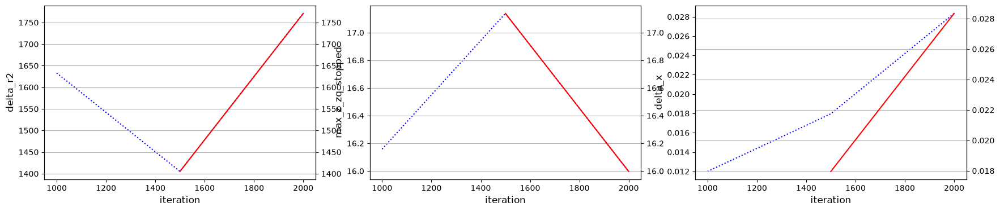

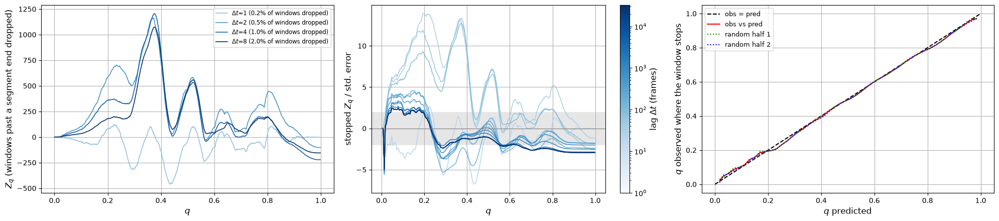

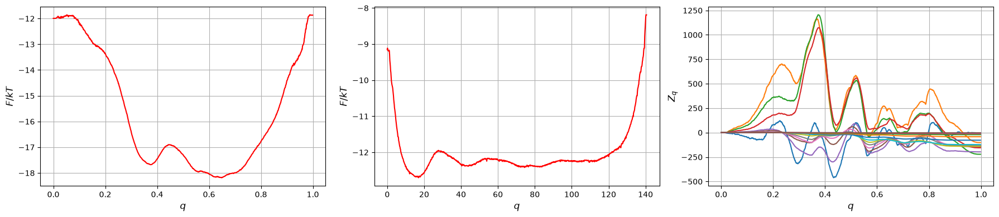

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


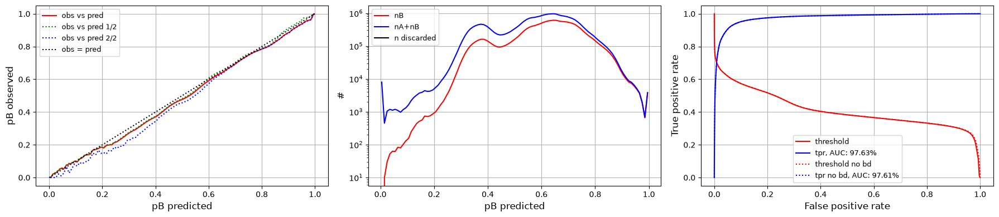

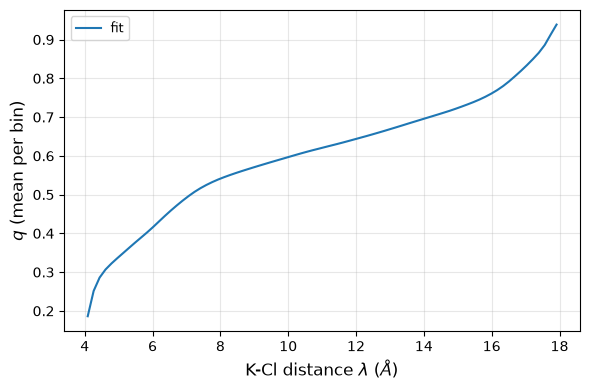

2000 iterations (warm-up, envelope 1) 
#=2500, dr2=1831.1, zqs_z=14.3621, sdzqs=323.412, |dx|=0.0364869, time=46.2829
#=3000, dr2=1729.36, zqs_z=13.7683, sdzqs=274.549, |dx|=0.0180235, time=92.5659
#=3500, dr2=1891.43, zqs_z=13.749, sdzqs=374.685, |dx|=0.0178743, time=138.437
#=4000, dr2=2036.53, zqs_z=17.6729, sdzqs=430.261, |dx|=0.0147433, time=184.946
#=4500, dr2=1797.39, zqs_z=13.9997, sdzqs=341.229, |dx|=0.00873107, time=230.847
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it4500 ---


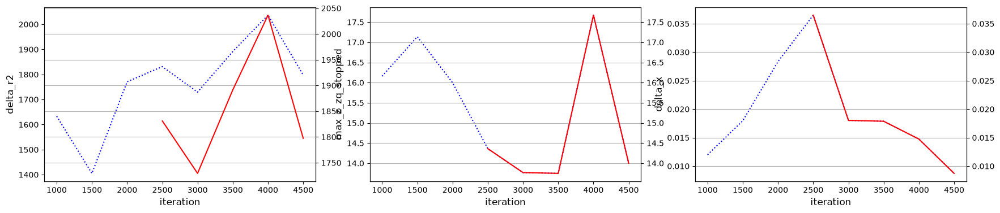

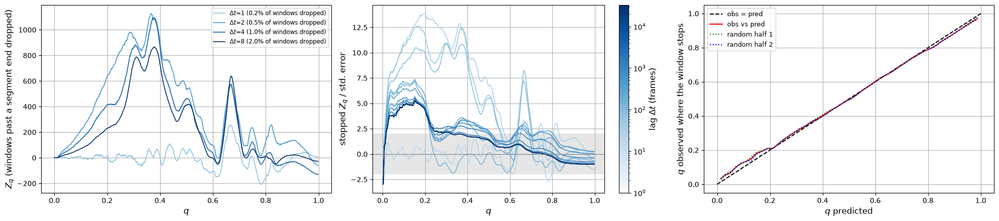

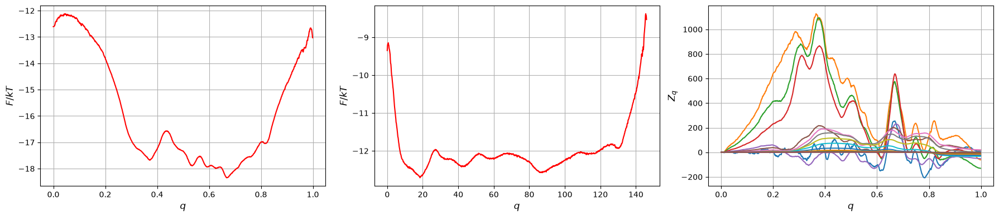

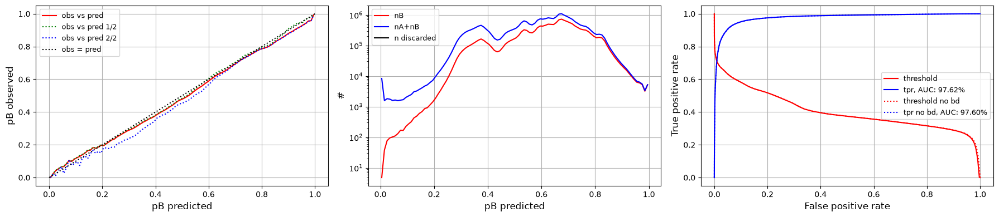

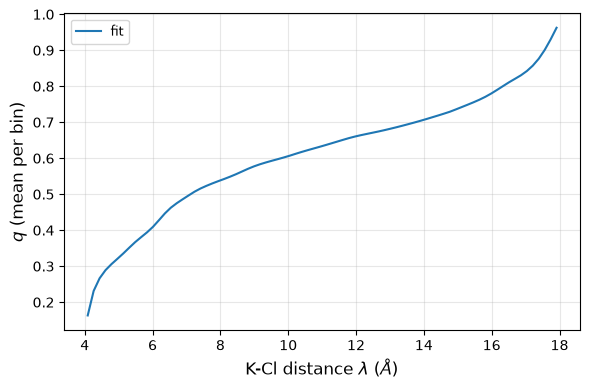

4500 iterations (main, envelope 0.01) 
#=5000, dr2=1824.14, zqs_z=13.7577, sdzqs=348.157, |dx|=0.0141685, time=45.8309
#=5500, dr2=1944.06, zqs_z=14.2788, sdzqs=406.458, |dx|=0.00796924, time=91.7123
#=6000, dr2=1878.63, zqs_z=14.0521, sdzqs=386.935, |dx|=0.00961674, time=137.626
#=6500, dr2=1961.82, zqs_z=15.1086, sdzqs=376.386, |dx|=0.0157816, time=183.532
#=7000, dr2=2016.5, zqs_z=13.8616, sdzqs=305.016, |dx|=0.0133797, time=230.037


/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it7000 ---


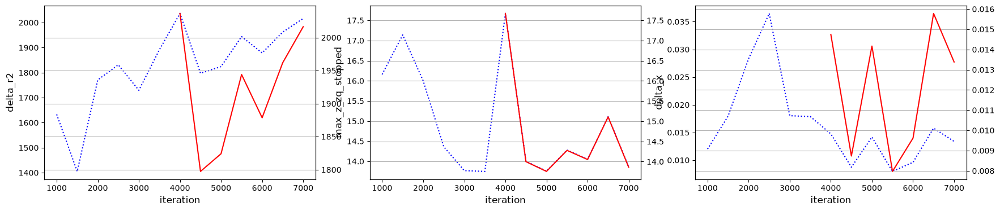

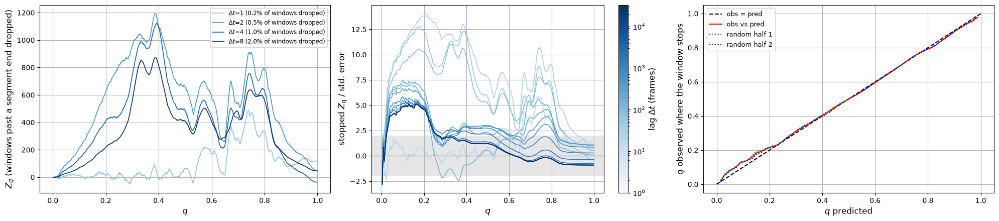

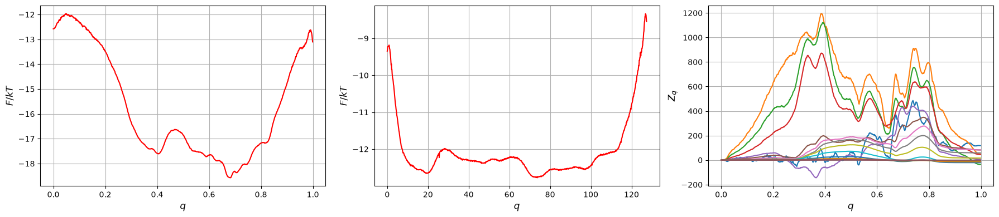

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


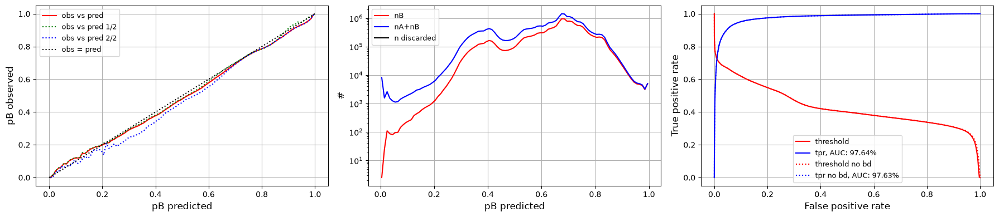

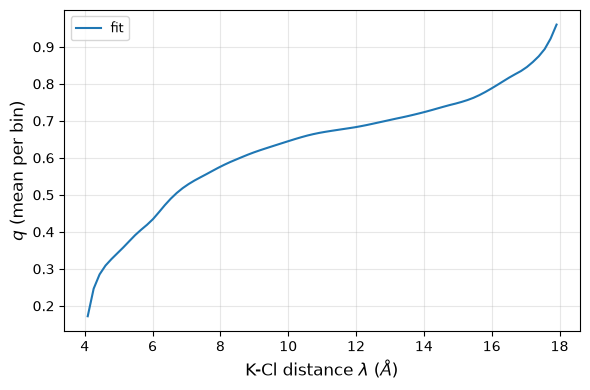

7000 iterations (main, envelope 0.01) 
#=7500, dr2=1974.95, zqs_z=13.893, sdzqs=412.379, |dx|=0.0088669, time=45.714
#=8000, dr2=2030.36, zqs_z=15.1098, sdzqs=446.648, |dx|=0.0089744, time=92.043
#=8500, dr2=2447.74, zqs_z=29.5287, sdzqs=1450.69, |dx|=0.0180499, time=138.14
#=9000, dr2=1910, zqs_z=16.575, sdzqs=395.578, |dx|=0.0193347, time=184.04
#=9500, dr2=1979.91, zqs_z=16.7051, sdzqs=547.71, |dx|=0.0092689, time=229.901
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it9500 ---


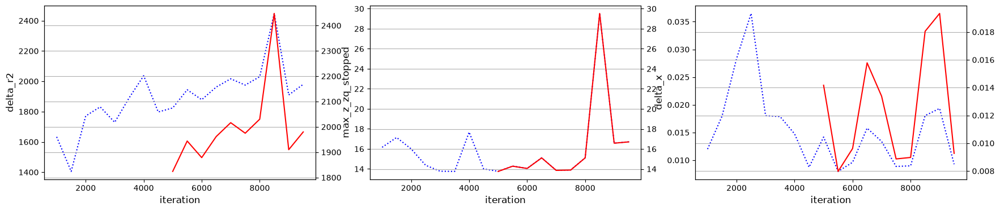

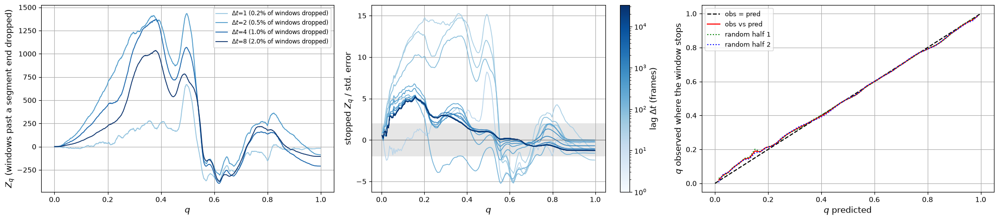

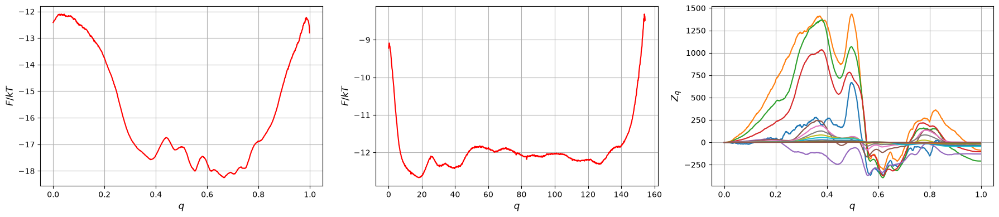

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


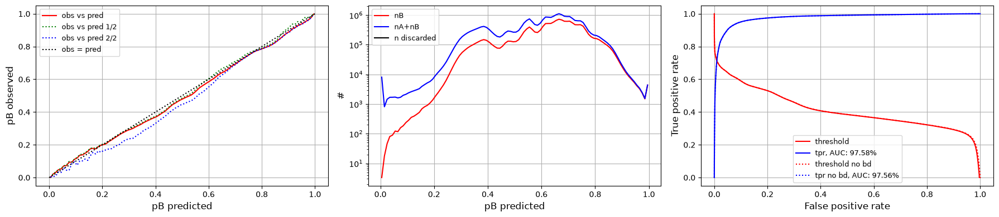

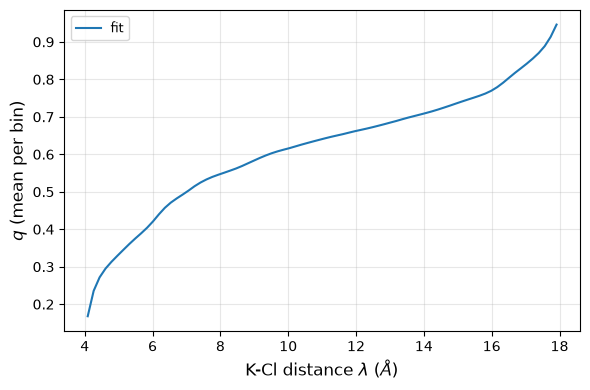

9500 iterations (main, envelope 0.01) 
#=10000, dr2=1862.09, zqs_z=17.5474, sdzqs=316.433, |dx|=0.0121865, time=45.5788
#=10500, dr2=1796.75, zqs_z=13.8517, sdzqs=367.339, |dx|=0.0157222, time=91.4427
#=11000, dr2=1747.91, zqs_z=14.1268, sdzqs=263.574, |dx|=0.00585049, time=137.271
#=11500, dr2=1602.45, zqs_z=14.2894, sdzqs=376.713, |dx|=0.012153, time=183.086
#=12000, dr2=2049.08, zqs_z=14.9404, sdzqs=404.151, |dx|=0.0216102, time=228.948
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it12000 ---


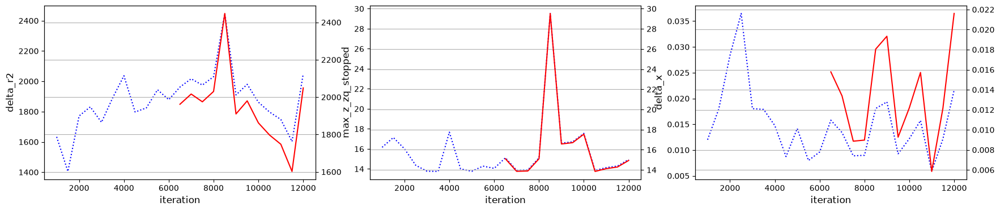

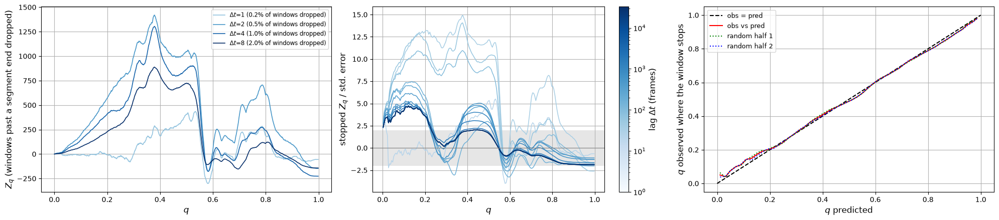

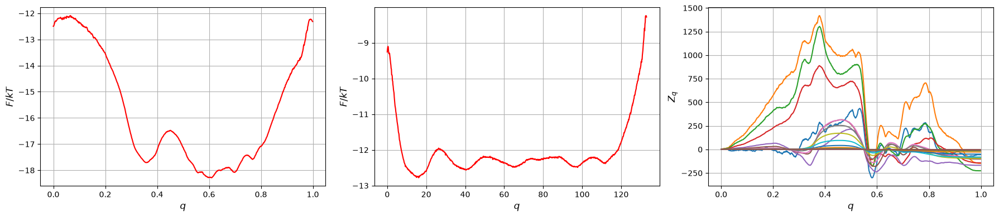

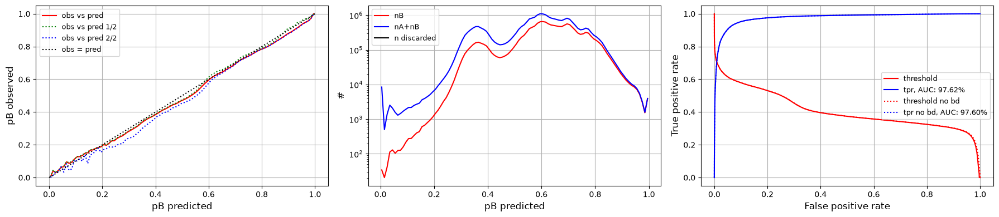

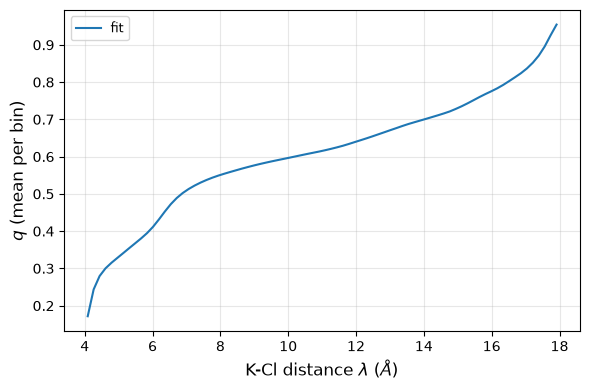

12000 iterations (main, envelope 0.01) 
#=12500, dr2=1801.79, zqs_z=13.4463, sdzqs=289.053, |dx|=0.0236956, time=46.2624
#=13000, dr2=1875.15, zqs_z=13.5262, sdzqs=341.048, |dx|=0.00852477, time=92.843
#=13500, dr2=1990.94, zqs_z=16.9396, sdzqs=439.441, |dx|=0.0111407, time=139.498
#=14000, dr2=1947.96, zqs_z=14.3495, sdzqs=390.228, |dx|=0.0118749, time=186.083
#=14500, dr2=1960.6, zqs_z=13.7563, sdzqs=309.692, |dx|=0.0121822, time=232.709
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it14500 ---


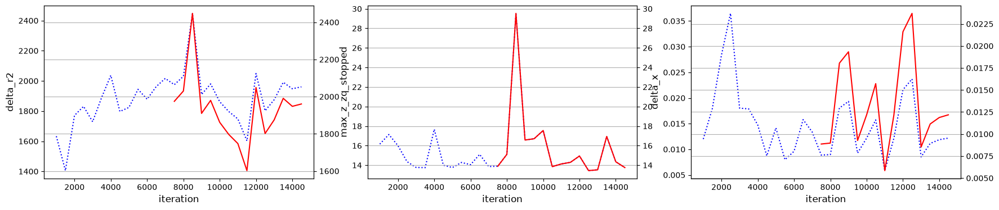

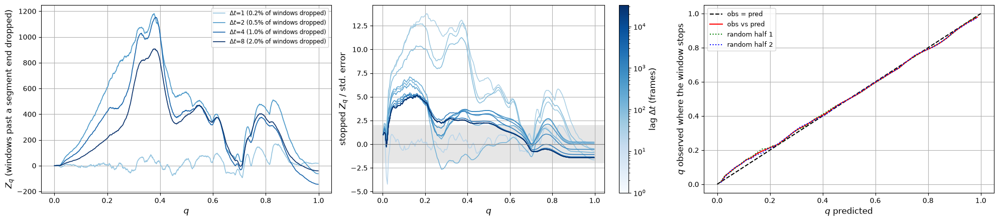

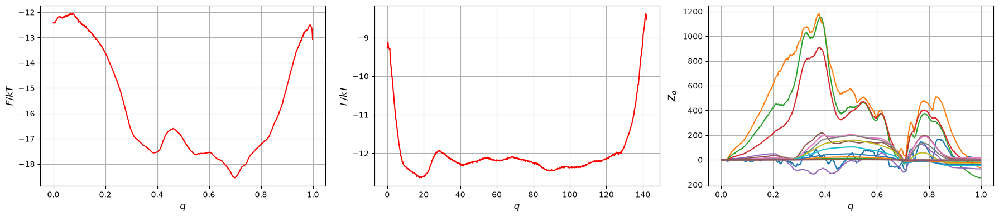

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


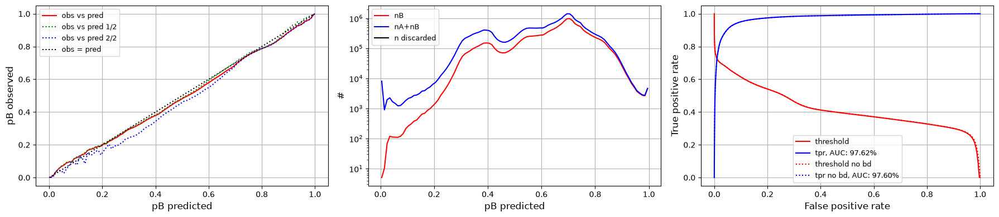

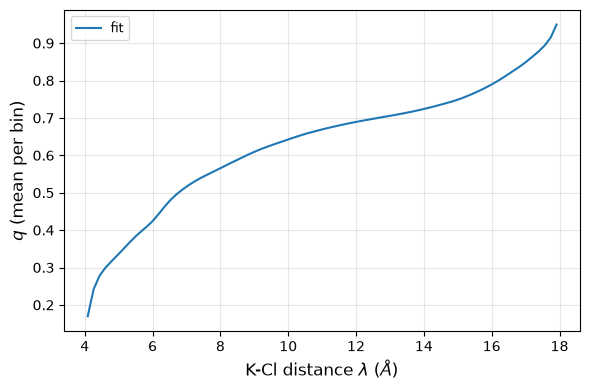

14500 iterations (main, envelope 0.01) 
#=15000, dr2=1931.24, zqs_z=14.2765, sdzqs=272.267, |dx|=0.0115152, time=46.1163
#=15500, dr2=2112.22, zqs_z=32.3115, sdzqs=994.748, |dx|=0.0485162, time=92.5257
#=16000, dr2=1988.71, zqs_z=32.0798, sdzqs=1506.61, |dx|=0.0237797, time=138.149
#=16500, dr2=1733.03, zqs_z=13.4882, sdzqs=263.304, |dx|=0.0175679, time=183.83
#=17000, dr2=1768.64, zqs_z=13.9045, sdzqs=290.69, |dx|=0.0149731, time=229.502
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/kcl_dissociation/infretis_staple/kcl_staple/rejections/seedhist0/it17000 ---


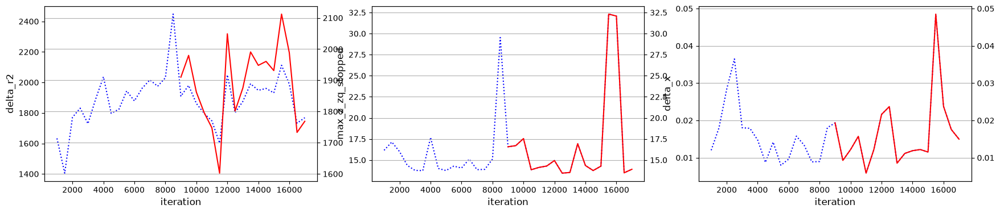

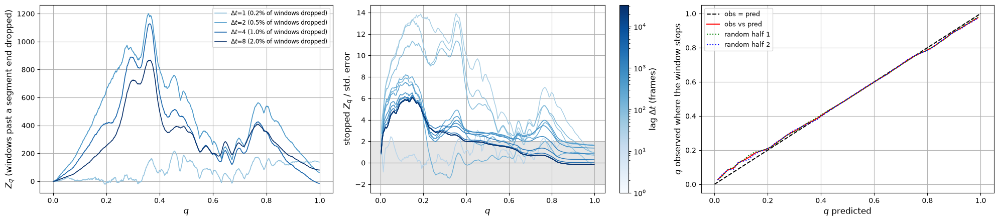

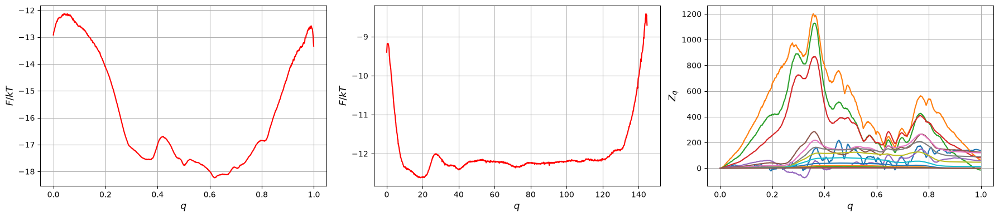

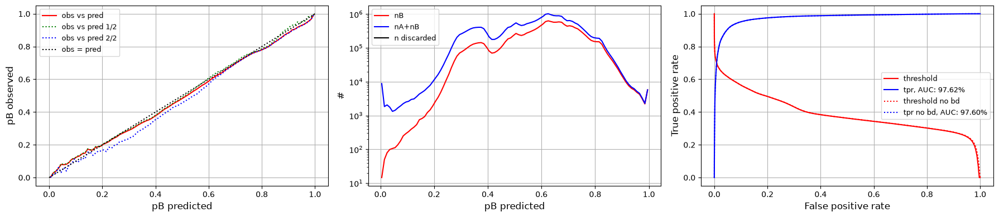

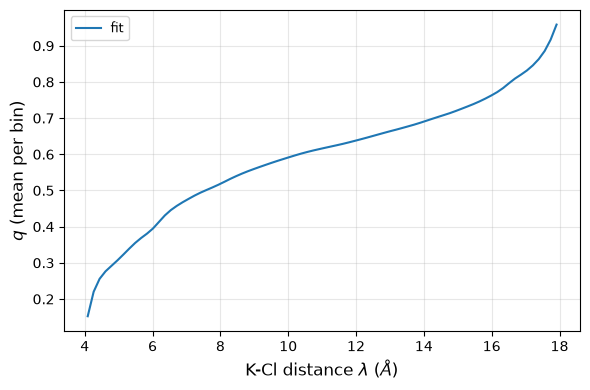

17000 iterations (main, envelope 0.01) 


In [7]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
history=[0,2,4,8,16]
yr_type=['y(t-d),y(t)']
fits = {}                                      # weighting -> final q per seed, exact committor, fit time, zqs_z history
for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    #qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    qe = None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seedhist{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=WARMUP_ITER, 
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            delta_r2_max_change_allowed=10000, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=n_iter, 
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

## 7. Results

**Table:** per weighting and seed, the data size, the final and lowest `zqs_z` of the run (its own data; about 2 or less is consistent), and with the exact committor the path-weighted RMS of fit − exact over the frames with 0.05 < q_exact < 0.95 and over the bins in that range.

**Committor along λ:** the path-weighted mean q per λ bin of every fit, the exact committor averaged the same way (dashed), and fit − exact.

,,paths,pieces,frames,zqs_z_final,zqs_z_min,fit_minutes
weighting,seed,,,,,,
rejections,0,4240,8657,3370265,7.0315,6.4689,1.2877


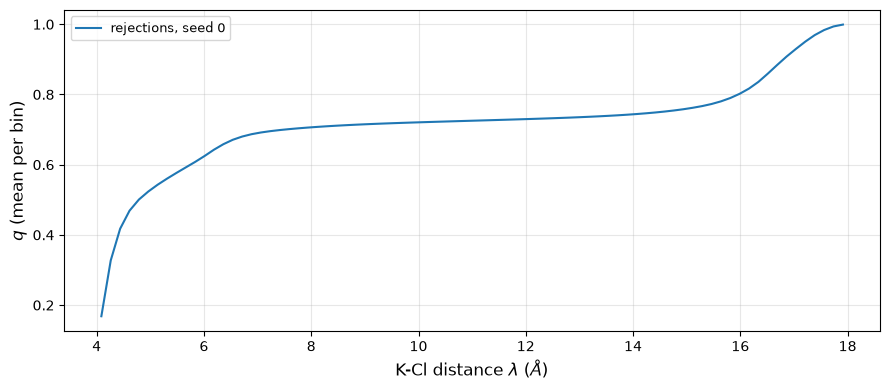

In [9]:
rows, profiles = [], {}
for name, fit in fits.items():
    d = datas[name]
    fr = ~(d.boundary0 | d.boundary1)
    edges = edges_for(d)
    bm = seed_runs.BinnedMean((d.lam,), edges[:1], fr)
    w_mean = bm(d.path_weights)
    qe = fit['q_exact']
    for s, r in fit['r'].items():
        row = dict(weighting=name, seed=s, paths=len(np.unique(d.group_traj)), pieces=int(d.i_traj.max() + 1),
                   frames=len(r), zqs_z_final=fit['zqs_z'][-1], zqs_z_min=fit['zqs_z'][1:].min(),
                   fit_minutes=fit['t_fit'] / 60 / len(fit['r']))
        profiles[(name, s)] = bm(d.path_weights * r) / w_mean
        if qe is not None:
            t = fr & (qe > 0.05) & (qe < 0.95)
            row['rms_frames'] = np.sqrt(np.sum(d.path_weights[t] * (r[t] - qe[t]) ** 2) / np.sum(d.path_weights[t]))
            pe = bm(d.path_weights * qe) / w_mean
            tb = (pe > 0.05) & (pe < 0.95)
            row['rms_bins_lambda'] = np.sqrt(np.nanmean((profiles[(name, s)] - pe)[tb] ** 2))
            profiles[('exact', name)] = pe
        rows.append(row)
summary = pd.DataFrame(rows).set_index(['weighting', 'seed'])
os.makedirs(OUT, exist_ok=True)
summary.to_csv(f'{OUT}/summary.csv')
display(summary.round(4))

edges = edges_for(data)
mid = (edges[0][1:] + edges[0][:-1]) / 2
has_exact = any(k[0] == 'exact' for k in profiles)
fig, axes = plt.subplots(2 if has_exact else 1, 1, figsize=(9, 7 if has_exact else 4), sharex=True, squeeze=False)
for (name, s), P in profiles.items():
    if name == 'exact':
        continue
    axes[0, 0].plot(mid, P, label=f'{name}, seed {s}')
    if has_exact:
        axes[1, 0].plot(mid, P - profiles[('exact', name)], label=f'{name}, seed {s}')
if has_exact:
    axes[0, 0].plot(mid, profiles[('exact', next(iter(fits)))], 'k--', label='exact')
    axes[1, 0].axhline(0, color='k', lw=0.8)
    axes[1, 0].set(ylabel='fit $-$ exact')
    axes[1, 0].grid(alpha=0.3)
axes[0, 0].set(ylabel='$q$ (mean per bin)')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)
axes[-1, 0].set(xlabel=XLABEL)
fig.tight_layout()
fig.savefig(f'{OUT}/profiles.png', dpi=110)
plt.show()

## 8. Save

Every fit's q per frame with its frames, in the format of `load_tis_data_cupy.py`'s `committor.npz` (`r`, `lam`, `X_all`, `i_traj`, `t_traj`, `group_traj`, `path_weights`, `boundary0`, `boundary1`), as `<OUT>/<weighting>/seed<s>/committor.npz`. (`run_seeds` also saved each final q alone as `q_traj.npy`.)

In [ ]:
for name, fit in fits.items():
    d = datas[name]
    for s, r in fit['r'].items():
        path = f'{OUT}/{name}/seed{s}/committor.npz'
        np.savez(path, r=r, lam=d.lam, X_all=d.X_all, i_traj=d.i_traj, t_traj=d.t_traj, group_traj=d.group_traj,
                 path_weights=d.path_weights, boundary0=d.boundary0, boundary1=d.boundary1,
                 weighting=name, tis_dir=TIS_DIR)
        print('saved', path)